# 🔬 Breast Cancer Classification: A Complete Data Science Walkthrough

## Introduction

Welcome to this comprehensive tutorial on Exploratory Data Analysis (EDA) and statistical testing for a classification problem. This notebook is designed for team members with **no prior data science experience** and will guide you through the entire process step-by-step.

### What We'll Learn

By the end of this notebook, you'll understand:

1. **Data Understanding** - What is our data? What does each column mean?
2. **Data Cleaning** - How to handle missing values, duplicates, and data quality issues
3. **Exploratory Data Analysis (EDA)** - Visualizing and understanding patterns in data
4. **Statistical Testing** - How to scientifically validate our observations
5. **Feature Analysis** - Which features are most important for prediction?

### The Business Problem

We have measurements from breast cancer biopsies. Our goal is to **predict whether a tumor is Malignant (M) or Benign (B)** based on various cell characteristics.

- **Malignant (M)**: Cancerous tumors that can spread to other parts of the body
- **Benign (B)**: Non-cancerous tumors that don't spread

This is a **binary classification problem** - we're predicting one of two possible outcomes.

---

## Part 1: Setting Up Our Environment

### What are Libraries?

Libraries are pre-written code packages that give us tools to work with data. Think of them as toolboxes - instead of building every tool from scratch, we use tools others have already created.

**Our main libraries:**
- `pandas` - For data manipulation (like Excel on steroids)
- `numpy` - For numerical computations
- `matplotlib` & `seaborn` - For creating visualizations
- `scipy` - For statistical tests
- `warnings` - To keep our output clean

In [1]:
# =============================================================================
# IMPORTING LIBRARIES
# =============================================================================
# Think of this as gathering your tools before starting a project

import pandas as pd                    # Data manipulation and analysis
import numpy as np                     # Numerical operations
import matplotlib.pyplot as plt        # Basic plotting
import seaborn as sns                  # Beautiful statistical visualizations
from scipy import stats                # Statistical tests
from scipy.stats import (
    shapiro,           # Test for normal distribution
    mannwhitneyu,      # Non-parametric test for comparing groups
    ttest_ind,         # T-test for comparing means
    chi2_contingency,  # Chi-square test for categorical variables
    spearmanr,         # Correlation for non-normal data
    pearsonr,          # Correlation for normal data
    levene             # Test for equal variances
)
import warnings
warnings.filterwarnings('ignore')      # Hide warning messages for cleaner output

# Set visualization style for consistent, professional-looking plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')                # Use a colorblind-friendly palette

# Configure pandas to display more information
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.width', None)        # No line wrapping

print("✅ All libraries loaded successfully!")

✅ All libraries loaded successfully!


---

## Part 2: Loading and Understanding the Data

### The Wisconsin Breast Cancer Dataset

This is a famous dataset in machine learning. It contains measurements computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. The features describe characteristics of the cell nuclei present in the image.

### Feature Categories

For each cell nucleus, 10 real-valued features are computed:

| Feature | Description |
|---------|-------------|
| radius | Mean distance from center to perimeter |
| texture | Standard deviation of gray-scale values |
| perimeter | Perimeter of the nucleus |
| area | Area of the nucleus |
| smoothness | Local variation in radius lengths |
| compactness | perimeter² / area - 1.0 |
| concavity | Severity of concave portions of the contour |
| concave points | Number of concave portions of the contour |
| symmetry | Symmetry of the nucleus |
| fractal dimension | "Coastline approximation" - 1 |

For each feature, three values are computed:
- **mean**: Average value
- **se (standard error)**: Variation/uncertainty in the measurement
- **worst**: Largest (mean of the three largest values)

In [2]:
# =============================================================================
# LOADING THE DATA
# =============================================================================

# pd.read_csv() reads a CSV file and creates a DataFrame (a table of data)
df = pd.read_csv('dataset1.csv')

# Let's see the first 5 rows to understand what our data looks like
print("📊 First 5 rows of our dataset:")
print("="*80)
df.head()

📊 First 5 rows of our dataset:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# =============================================================================
# BASIC DATA INFORMATION
# =============================================================================

print("📋 DATASET OVERVIEW")
print("="*80)
print(f"\n🔢 Number of samples (rows): {df.shape[0]}")
print(f"📏 Number of features (columns): {df.shape[1]}")
print(f"\n📝 Column names and their data types:")
print("-"*80)
print(df.dtypes)

📋 DATASET OVERVIEW

🔢 Number of samples (rows): 569
📏 Number of features (columns): 32

📝 Column names and their data types:
--------------------------------------------------------------------------------
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst            

🎯 TARGET VARIABLE ANALYSIS: 'diagnosis'

Distribution of diagnoses:
  • Benign (B):    357 samples (62.7%)
  • Malignant (M): 212 samples (37.3%)


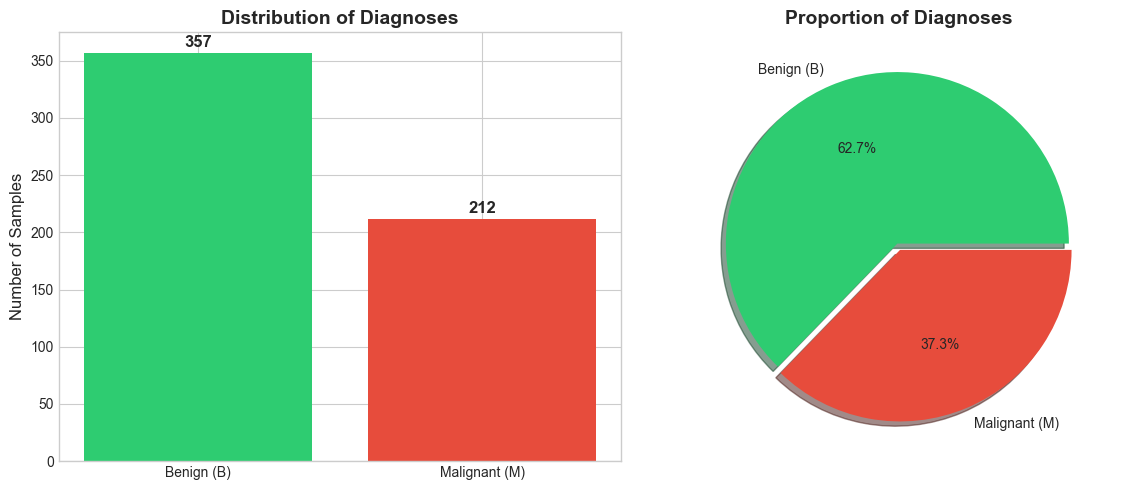


💡 INSIGHT: Our dataset is slightly imbalanced with more Benign cases.
   This is important to consider when building our model later.


In [4]:
# =============================================================================
# UNDERSTANDING OUR TARGET VARIABLE
# =============================================================================
# The 'diagnosis' column is what we want to predict - this is called the "target variable"

print("🎯 TARGET VARIABLE ANALYSIS: 'diagnosis'")
print("="*80)

# Count how many of each type we have
diagnosis_counts = df['diagnosis'].value_counts()
print(f"\nDistribution of diagnoses:")
print(f"  • Benign (B):    {diagnosis_counts['B']} samples ({diagnosis_counts['B']/len(df)*100:.1f}%)")
print(f"  • Malignant (M): {diagnosis_counts['M']} samples ({diagnosis_counts['M']/len(df)*100:.1f}%)")

# Visualize the class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
colors = ['#2ecc71', '#e74c3c']  # Green for Benign, Red for Malignant
axes[0].bar(['Benign (B)', 'Malignant (M)'], [diagnosis_counts['B'], diagnosis_counts['M']], color=colors)
axes[0].set_ylabel('Number of Samples', fontsize=12)
axes[0].set_title('Distribution of Diagnoses', fontsize=14, fontweight='bold')
for i, v in enumerate([diagnosis_counts['B'], diagnosis_counts['M']]):
    axes[0].text(i, v + 5, str(v), ha='center', fontsize=12, fontweight='bold')

# Pie chart
axes[1].pie([diagnosis_counts['B'], diagnosis_counts['M']], 
            labels=['Benign (B)', 'Malignant (M)'],
            autopct='%1.1f%%',
            colors=colors,
            explode=(0.02, 0.02),
            shadow=True)
axes[1].set_title('Proportion of Diagnoses', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n💡 INSIGHT: Our dataset is slightly imbalanced with more Benign cases.")
print("   This is important to consider when building our model later.")

---

## Part 3: Data Cleaning

### Why Data Cleaning Matters

"Garbage in, garbage out" - If our data has problems, our analysis and models will also have problems. Data cleaning involves:

1. **Handling missing values** - Empty cells in our data
2. **Removing duplicates** - Repeated records
3. **Fixing data types** - Ensuring numbers are stored as numbers, etc.
4. **Identifying outliers** - Extreme values that might be errors
5. **Standardizing formats** - Consistent naming, units, etc.

In [5]:
# =============================================================================
# CHECK FOR MISSING VALUES
# =============================================================================
# Missing values (NaN = Not a Number) are empty cells in our data

print("🔍 MISSING VALUE ANALYSIS")
print("="*80)

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_percentage
})

# Show only columns with missing values (if any)
missing_with_values = missing_df[missing_df['Missing Count'] > 0]

if len(missing_with_values) == 0:
    print("\n✅ Great news! No missing values found in the dataset.")
else:
    print("\n⚠️ Columns with missing values:")
    print(missing_with_values)

print(f"\n📊 Total missing values across entire dataset: {df.isnull().sum().sum()}")

🔍 MISSING VALUE ANALYSIS

✅ Great news! No missing values found in the dataset.

📊 Total missing values across entire dataset: 0


In [6]:
# =============================================================================
# CHECK FOR DUPLICATE ROWS
# =============================================================================
# Duplicates can skew our analysis and overfit our models

print("🔍 DUPLICATE ANALYSIS")
print("="*80)

# Check for exact duplicates (all columns identical)
duplicates = df.duplicated().sum()
print(f"\n📊 Number of exact duplicate rows: {duplicates}")

# Check for duplicate IDs (should be unique for each patient)
duplicate_ids = df['id'].duplicated().sum()
print(f"📊 Number of duplicate patient IDs: {duplicate_ids}")

if duplicates == 0 and duplicate_ids == 0:
    print("\n✅ No duplicates found. Each row represents a unique sample.")
else:
    print("\n⚠️ Duplicates detected! We should investigate and remove them.")

🔍 DUPLICATE ANALYSIS

📊 Number of exact duplicate rows: 0
📊 Number of duplicate patient IDs: 0

✅ No duplicates found. Each row represents a unique sample.


In [7]:
# =============================================================================
# DATA TYPE VERIFICATION AND COLUMN CLEANUP
# =============================================================================

print("🔧 DATA PREPARATION")
print("="*80)

# Create a clean copy of our dataframe
df_clean = df.copy()

# The 'id' column is just an identifier, not useful for prediction
# We'll keep it for reference but won't use it in analysis
print("\n📌 Step 1: Noting the 'id' column")
print("   The 'id' is a patient identifier - not useful for prediction.")
print("   We'll exclude it from our feature analysis.")

# Convert diagnosis to a more descriptive format for visualization
print("\n📌 Step 2: Creating numeric target variable")
df_clean['diagnosis_numeric'] = df_clean['diagnosis'].map({'M': 1, 'B': 0})
print("   Created 'diagnosis_numeric': M=1 (Malignant), B=0 (Benign)")

# Define our feature columns (excluding id and diagnosis)
feature_columns = [col for col in df_clean.columns if col not in ['id', 'diagnosis', 'diagnosis_numeric']]
print(f"\n📌 Step 3: Identified {len(feature_columns)} feature columns for analysis")

# Verify all features are numeric
print("\n📌 Step 4: Verifying data types")
non_numeric = df_clean[feature_columns].select_dtypes(exclude=[np.number]).columns.tolist()
if len(non_numeric) == 0:
    print("   ✅ All feature columns are numeric - ready for analysis!")
else:
    print(f"   ⚠️ Non-numeric columns found: {non_numeric}")

🔧 DATA PREPARATION

📌 Step 1: Noting the 'id' column
   The 'id' is a patient identifier - not useful for prediction.
   We'll exclude it from our feature analysis.

📌 Step 2: Creating numeric target variable
   Created 'diagnosis_numeric': M=1 (Malignant), B=0 (Benign)

📌 Step 3: Identified 30 feature columns for analysis

📌 Step 4: Verifying data types
   ✅ All feature columns are numeric - ready for analysis!


In [8]:
# =============================================================================
# ORGANIZING FEATURES BY CATEGORY
# =============================================================================
# Let's organize our features to make analysis easier

print("📂 FEATURE ORGANIZATION")
print("="*80)

# Group features by their measurement type
mean_features = [col for col in feature_columns if '_mean' in col]
se_features = [col for col in feature_columns if '_se' in col]
worst_features = [col for col in feature_columns if '_worst' in col]

print(f"\n📊 Features organized into 3 groups:")
print(f"\n1️⃣ MEAN features ({len(mean_features)} columns):")
print(f"   These represent the average measurement for each cell characteristic")
for f in mean_features:
    print(f"   • {f}")

print(f"\n2️⃣ STANDARD ERROR (SE) features ({len(se_features)} columns):")
print(f"   These represent the variation/uncertainty in measurements")
for f in se_features:
    print(f"   • {f}")

print(f"\n3️⃣ WORST features ({len(worst_features)} columns):")
print(f"   These represent the most extreme values (largest means)")
for f in worst_features:
    print(f"   • {f}")

📂 FEATURE ORGANIZATION

📊 Features organized into 3 groups:

1️⃣ MEAN features (10 columns):
   These represent the average measurement for each cell characteristic
   • radius_mean
   • texture_mean
   • perimeter_mean
   • area_mean
   • smoothness_mean
   • compactness_mean
   • concavity_mean
   • concave points_mean
   • symmetry_mean
   • fractal_dimension_mean

2️⃣ STANDARD ERROR (SE) features (10 columns):
   These represent the variation/uncertainty in measurements
   • radius_se
   • texture_se
   • perimeter_se
   • area_se
   • smoothness_se
   • compactness_se
   • concavity_se
   • concave points_se
   • symmetry_se
   • fractal_dimension_se

3️⃣ WORST features (10 columns):
   These represent the most extreme values (largest means)
   • radius_worst
   • texture_worst
   • perimeter_worst
   • area_worst
   • smoothness_worst
   • compactness_worst
   • concavity_worst
   • concave points_worst
   • symmetry_worst
   • fractal_dimension_worst


---

## Part 4: Descriptive Statistics

### What are Descriptive Statistics?

Descriptive statistics summarize and describe the main features of a dataset. Key measures include:

| Statistic | Description | What it tells us |
|-----------|-------------|------------------|
| **Mean** | Average value | Central tendency |
| **Median** | Middle value | Central tendency (robust to outliers) |
| **Std** | Standard deviation | How spread out the data is |
| **Min/Max** | Smallest/Largest values | Range of the data |
| **25%/75%** | Quartiles | Distribution spread |
| **Skewness** | Asymmetry of distribution | Whether data leans left or right |
| **Kurtosis** | "Tailedness" of distribution | How extreme the outliers are |

In [9]:
# =============================================================================
# COMPREHENSIVE STATISTICAL SUMMARY
# =============================================================================

print("📊 DESCRIPTIVE STATISTICS")
print("="*80)

# Basic statistics for all numeric columns
stats_summary = df_clean[feature_columns].describe()

# Add additional useful statistics
stats_summary.loc['range'] = stats_summary.loc['max'] - stats_summary.loc['min']
stats_summary.loc['skewness'] = df_clean[feature_columns].skew()
stats_summary.loc['kurtosis'] = df_clean[feature_columns].kurtosis()

print("\n📈 Summary Statistics for All Features:")
print("-"*80)
# Display transposed for better readability (features as rows)
stats_summary.T.round(4)

📊 DESCRIPTIVE STATISTICS

📈 Summary Statistics for All Features:
--------------------------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max,range,skewness,kurtosis
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100,21.1290,0.9424,0.8455
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800,29.5700,0.6504,0.7583
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000,144.7100,0.9907,0.9722
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000,2357.5000,1.6457,3.6523
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634,0.1108,0.4563,0.8560
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454,0.3260,1.1901,1.6501
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268,0.4268,1.4012,1.9986
concave points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012,0.2012,1.1712,1.0666
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040,0.1980,0.7256,1.2879
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974,0.0475,1.3045,3.0059


In [10]:
# =============================================================================
# COMPARING STATISTICS BY DIAGNOSIS
# =============================================================================
# This is crucial - we want to see how features differ between M and B

print("📊 STATISTICS BY DIAGNOSIS (Malignant vs Benign)")
print("="*80)

# Calculate mean values for each diagnosis
comparison_df = df_clean.groupby('diagnosis')[feature_columns].agg(['mean', 'std']).round(4)

# Create a more readable comparison for mean features
print("\n🔬 Comparing MEAN values for 'mean' features:")
print("-"*80)

comparison_table = pd.DataFrame()
for feature in mean_features:
    comparison_table.loc[feature, 'Benign (B) - Mean'] = df_clean[df_clean['diagnosis']=='B'][feature].mean()
    comparison_table.loc[feature, 'Malignant (M) - Mean'] = df_clean[df_clean['diagnosis']=='M'][feature].mean()
    comparison_table.loc[feature, 'Difference (M-B)'] = (
        df_clean[df_clean['diagnosis']=='M'][feature].mean() - 
        df_clean[df_clean['diagnosis']=='B'][feature].mean()
    )
    comparison_table.loc[feature, '% Difference'] = (
        (df_clean[df_clean['diagnosis']=='M'][feature].mean() - 
         df_clean[df_clean['diagnosis']=='B'][feature].mean()) / 
        df_clean[df_clean['diagnosis']=='B'][feature].mean() * 100
    )

comparison_table = comparison_table.round(4)
comparison_table

📊 STATISTICS BY DIAGNOSIS (Malignant vs Benign)

🔬 Comparing MEAN values for 'mean' features:
--------------------------------------------------------------------------------


,Benign (B) - Mean,Malignant (M) - Mean,Difference (M-B),% Difference
radius_mean,12.1465,17.4628,5.3163,43.7681
texture_mean,17.9148,21.6049,3.6901,20.5983
perimeter_mean,78.0754,115.3654,37.2900,47.7615
area_mean,462.7902,978.3764,515.5862,111.4082
smoothness_mean,0.0925,0.1029,0.0104,11.2685
compactness_mean,0.0801,0.1452,0.0651,81.2930
concavity_mean,0.0461,0.1608,0.1147,249.0730
concave points_mean,0.0257,0.0880,0.0623,242.1418
symmetry_mean,0.1742,0.1929,0.0187,10.7488
fractal_dimension_mean,0.0629,0.0627,-0.0002,-0.2979


📊 PERCENTAGE DIFFERENCE VISUALIZATION

This chart shows how much LARGER (positive) or SMALLER (negative)
Malignant tumor measurements are compared to Benign tumors.


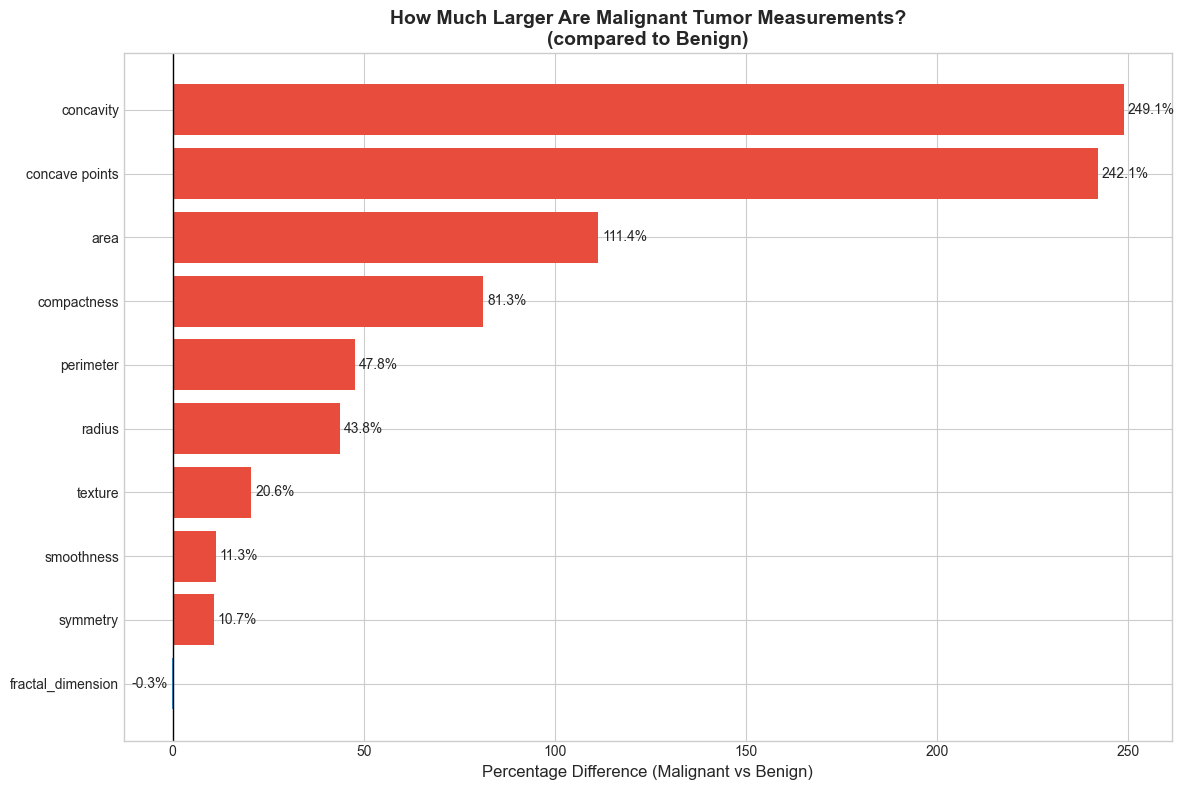


💡 INSIGHT: Malignant tumors generally have LARGER measurements,
   especially for 'concave points', 'area', 'perimeter', and 'concavity'.
   This makes biological sense - cancer cells tend to be larger and more irregular.


In [11]:
# =============================================================================
# VISUALIZE THE DIFFERENCES
# =============================================================================

print("📊 PERCENTAGE DIFFERENCE VISUALIZATION")
print("="*80)
print("\nThis chart shows how much LARGER (positive) or SMALLER (negative)")
print("Malignant tumor measurements are compared to Benign tumors.")

fig, ax = plt.subplots(figsize=(12, 8))

# Sort by percentage difference
sorted_comparison = comparison_table.sort_values('% Difference', ascending=True)

# Create horizontal bar chart
colors = ['#e74c3c' if x > 0 else '#3498db' for x in sorted_comparison['% Difference']]
bars = ax.barh(range(len(sorted_comparison)), sorted_comparison['% Difference'], color=colors)

# Customize the plot
ax.set_yticks(range(len(sorted_comparison)))
ax.set_yticklabels([f.replace('_mean', '') for f in sorted_comparison.index])
ax.set_xlabel('Percentage Difference (Malignant vs Benign)', fontsize=12)
ax.set_title('How Much Larger Are Malignant Tumor Measurements?\n(compared to Benign)', 
             fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linewidth=1)

# Add value labels
for i, (bar, val) in enumerate(zip(bars, sorted_comparison['% Difference'])):
    ax.text(val + 1 if val > 0 else val - 1, i, f'{val:.1f}%', 
            va='center', ha='left' if val > 0 else 'right', fontsize=10)

plt.tight_layout()
plt.show()

print("\n💡 INSIGHT: Malignant tumors generally have LARGER measurements,")
print("   especially for 'concave points', 'area', 'perimeter', and 'concavity'.")
print("   This makes biological sense - cancer cells tend to be larger and more irregular.")

---

## Part 5: Exploratory Data Analysis (EDA)

### What is EDA?

EDA is the process of investigating data to:
- Discover patterns
- Spot anomalies
- Test hypotheses
- Check assumptions

We do this primarily through **visualizations** because our brains are excellent at recognizing visual patterns.

### 5.1 Distribution Analysis

**Understanding Distributions:**
- A distribution shows how values are spread across a range
- **Normal distribution** (bell curve): Most values near the center, fewer at extremes
- **Skewed distribution**: Values lean to one side
- Knowing the distribution helps us choose appropriate statistical tests later

📊 DISTRIBUTION ANALYSIS: Mean Features

These histograms show how values are distributed, split by diagnosis.
Overlapping areas make classification harder; separated areas are easier.


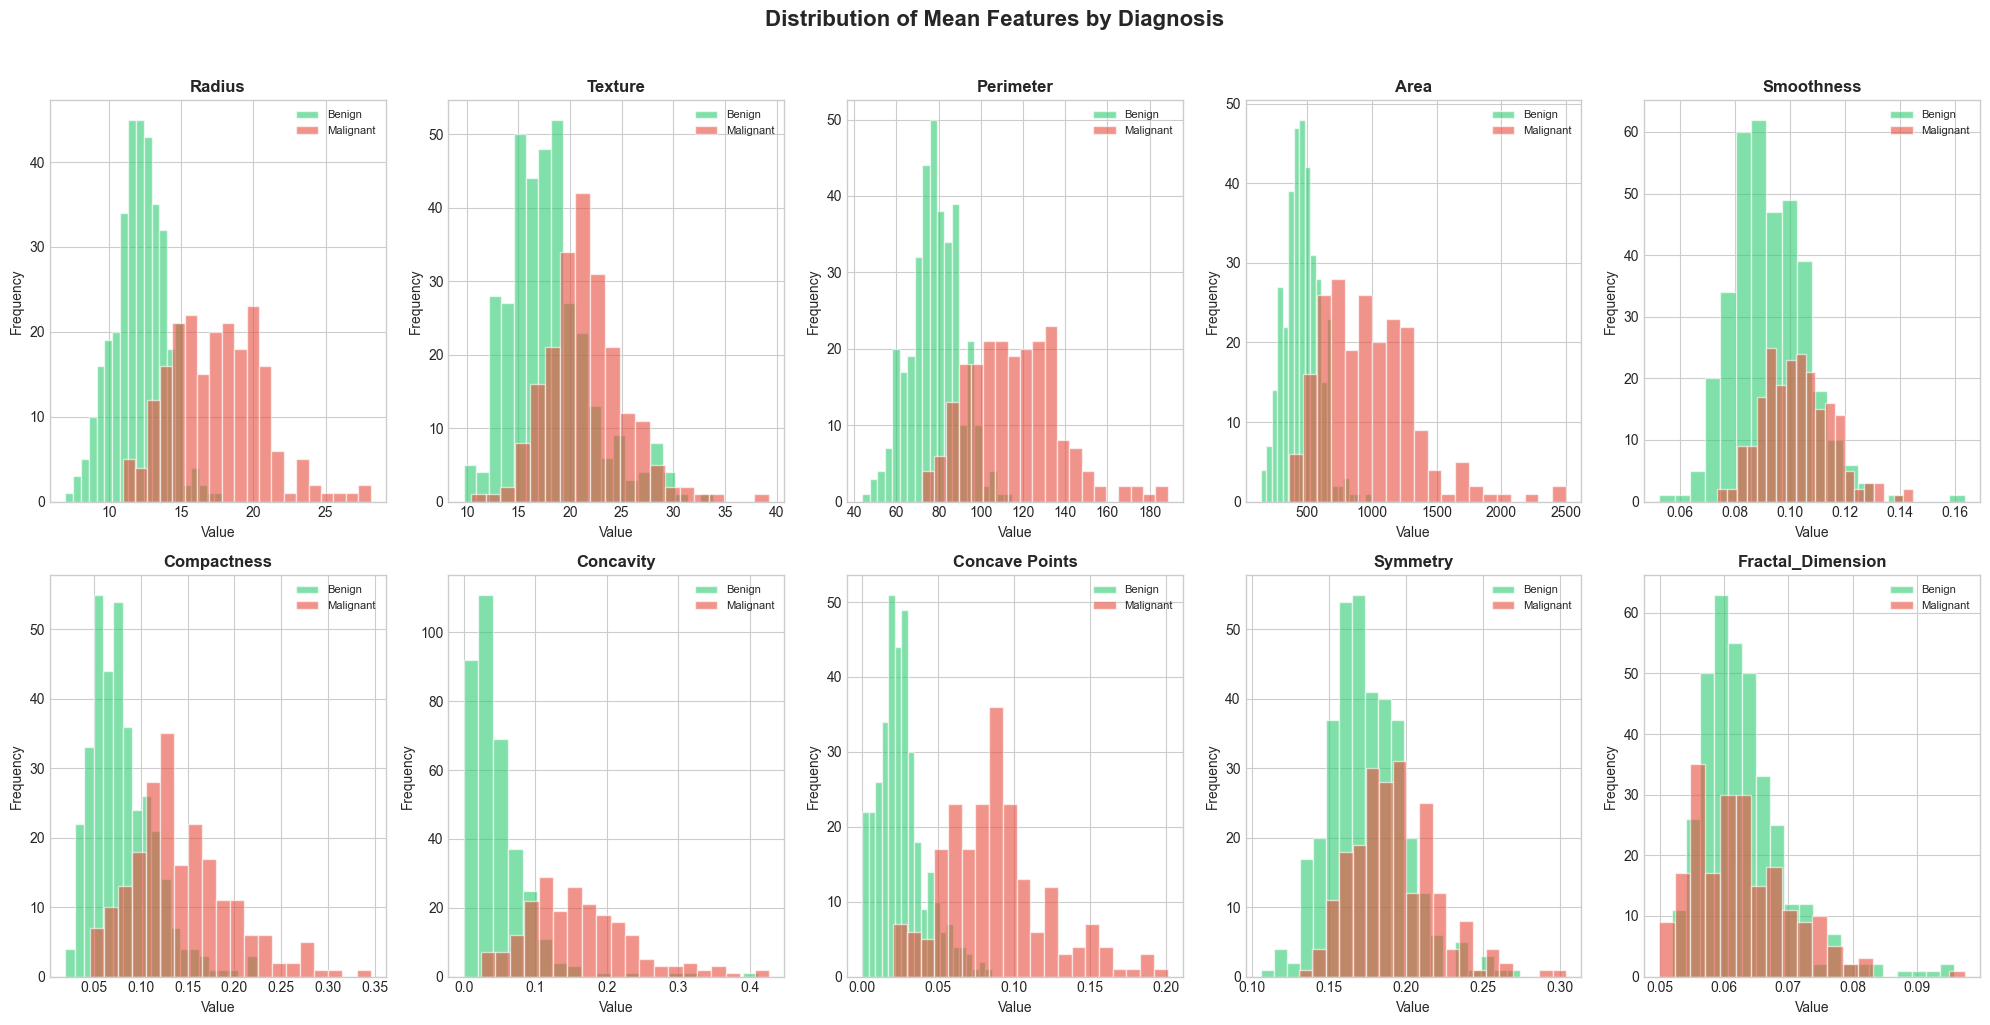


💡 INSIGHT: Features like 'concave points', 'area', and 'perimeter' show
   clear separation between Benign and Malignant - these will be important predictors!


In [12]:
# =============================================================================
# DISTRIBUTION PLOTS FOR MEAN FEATURES
# =============================================================================

print("📊 DISTRIBUTION ANALYSIS: Mean Features")
print("="*80)
print("\nThese histograms show how values are distributed, split by diagnosis.")
print("Overlapping areas make classification harder; separated areas are easier.")

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()

for idx, feature in enumerate(mean_features):
    ax = axes[idx]
    
    # Plot distributions for each diagnosis
    for diagnosis, color, label in [('B', '#2ecc71', 'Benign'), ('M', '#e74c3c', 'Malignant')]:
        data = df_clean[df_clean['diagnosis'] == diagnosis][feature]
        ax.hist(data, bins=20, alpha=0.6, color=color, label=label, edgecolor='white')
    
    ax.set_title(feature.replace('_mean', '').title(), fontsize=12, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)

plt.suptitle('Distribution of Mean Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n💡 INSIGHT: Features like 'concave points', 'area', and 'perimeter' show")
print("   clear separation between Benign and Malignant - these will be important predictors!")

📊 BOX PLOTS: Comparing Distributions by Diagnosis

📖 How to read a box plot:
   • Box: Contains 50% of data (25th to 75th percentile)
   • Line in box: Median (50th percentile)
   • Whiskers: Range of data (excluding outliers)
   • Dots: Outliers (unusual values)


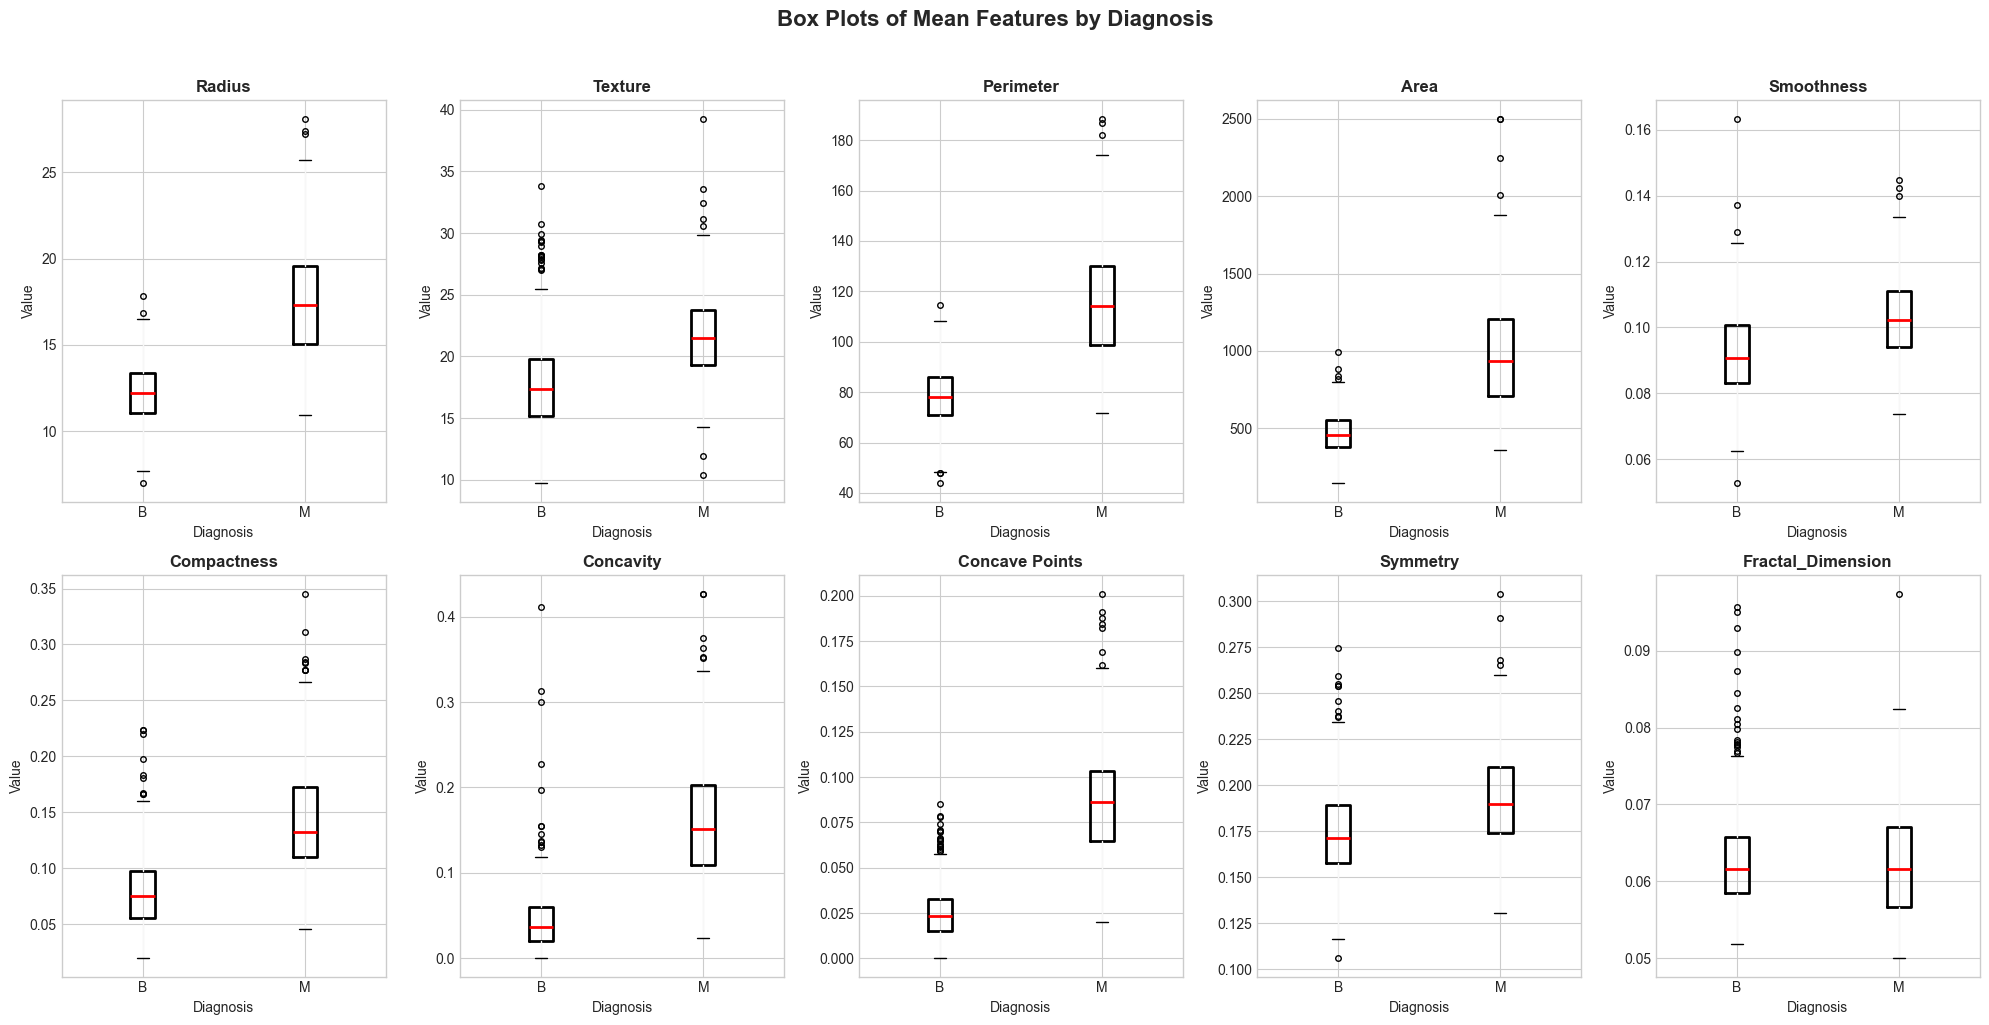


💡 INSIGHT: Notice how Malignant (M) boxes are often higher than Benign (B).
   Some features show very clear differences (area, perimeter, concave points).


In [13]:
# =============================================================================
# BOX PLOTS - COMPARING DISTRIBUTIONS
# =============================================================================

print("📊 BOX PLOTS: Comparing Distributions by Diagnosis")
print("="*80)
print("\n📖 How to read a box plot:")
print("   • Box: Contains 50% of data (25th to 75th percentile)")
print("   • Line in box: Median (50th percentile)")
print("   • Whiskers: Range of data (excluding outliers)")
print("   • Dots: Outliers (unusual values)")

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()

for idx, feature in enumerate(mean_features):
    ax = axes[idx]
    
    # Create box plot
    df_clean.boxplot(column=feature, by='diagnosis', ax=ax,
                     boxprops=dict(linewidth=2),
                     medianprops=dict(linewidth=2, color='red'),
                     flierprops=dict(marker='o', markersize=4))
    
    ax.set_title(feature.replace('_mean', '').title(), fontsize=12, fontweight='bold')
    ax.set_xlabel('Diagnosis')
    ax.set_ylabel('Value')

plt.suptitle('Box Plots of Mean Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n💡 INSIGHT: Notice how Malignant (M) boxes are often higher than Benign (B).")
print("   Some features show very clear differences (area, perimeter, concave points).")

📊 VIOLIN PLOTS: Distribution Shape Comparison

Violin plots combine box plots with density plots.
The width shows where values are most concentrated.


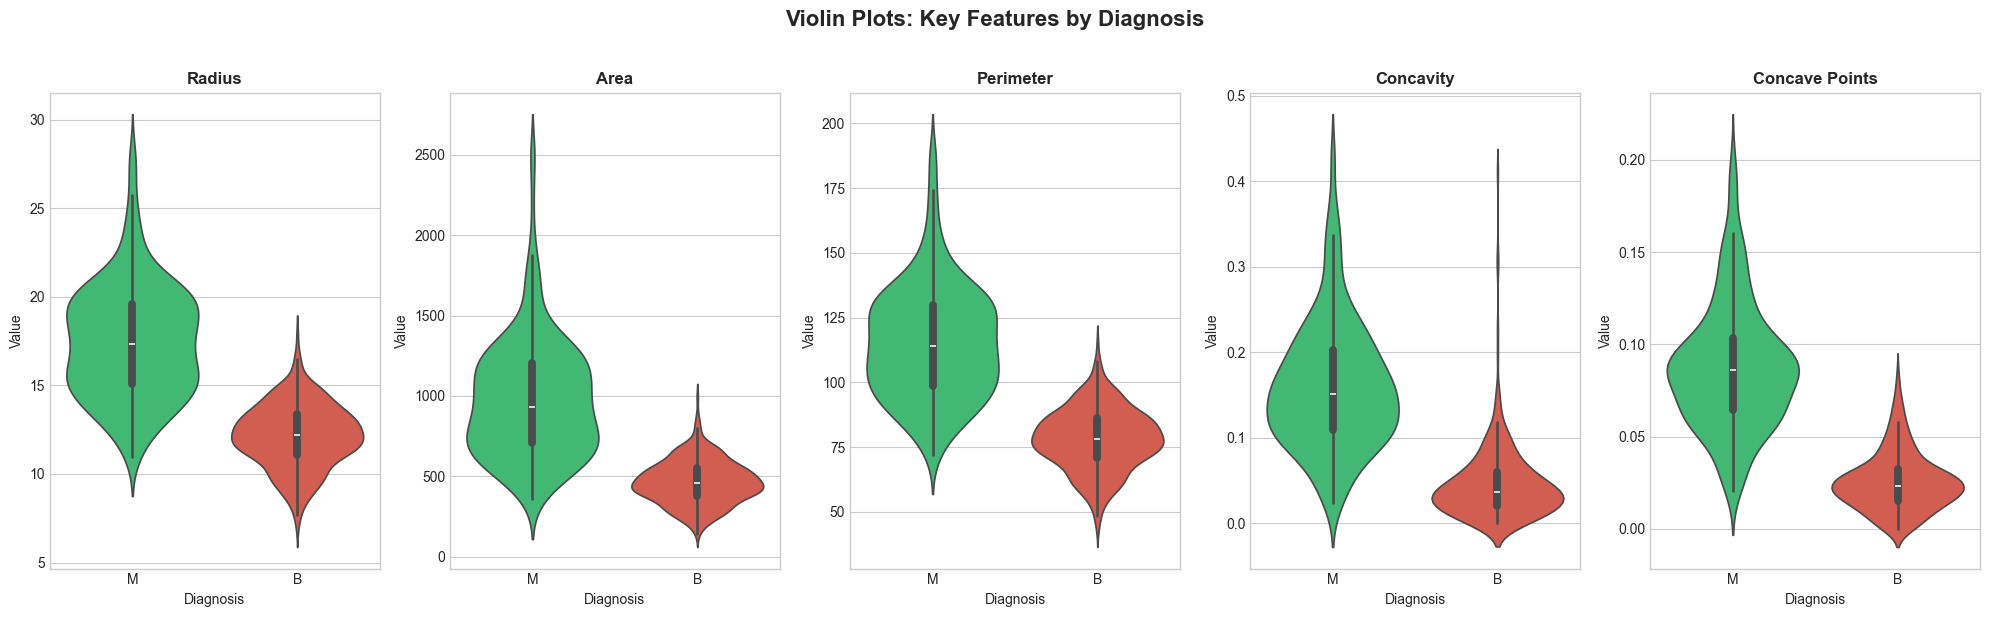

In [14]:
# =============================================================================
# VIOLIN PLOTS - DISTRIBUTION SHAPE COMPARISON
# =============================================================================

print("📊 VIOLIN PLOTS: Distribution Shape Comparison")
print("="*80)
print("\nViolin plots combine box plots with density plots.")
print("The width shows where values are most concentrated.")

# Select top features that show clear separation
top_features = ['radius_mean', 'area_mean', 'perimeter_mean', 
                'concavity_mean', 'concave points_mean']

fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for idx, feature in enumerate(top_features):
    ax = axes[idx]
    sns.violinplot(data=df_clean, x='diagnosis', y=feature, ax=ax,
                   palette=['#2ecc71', '#e74c3c'], inner='box')
    ax.set_title(feature.replace('_mean', '').title(), fontsize=12, fontweight='bold')
    ax.set_xlabel('Diagnosis')
    ax.set_ylabel('Value')

plt.suptitle('Violin Plots: Key Features by Diagnosis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.2 Correlation Analysis

**What is Correlation?**

Correlation measures how two variables move together:
- **+1**: Perfect positive correlation (both increase together)
- **0**: No correlation (no relationship)
- **-1**: Perfect negative correlation (one increases as other decreases)

**Why it matters:**
- Highly correlated features provide similar information (redundancy)
- Features correlated with our target are good predictors

📊 CORRELATION ANALYSIS: Mean Features


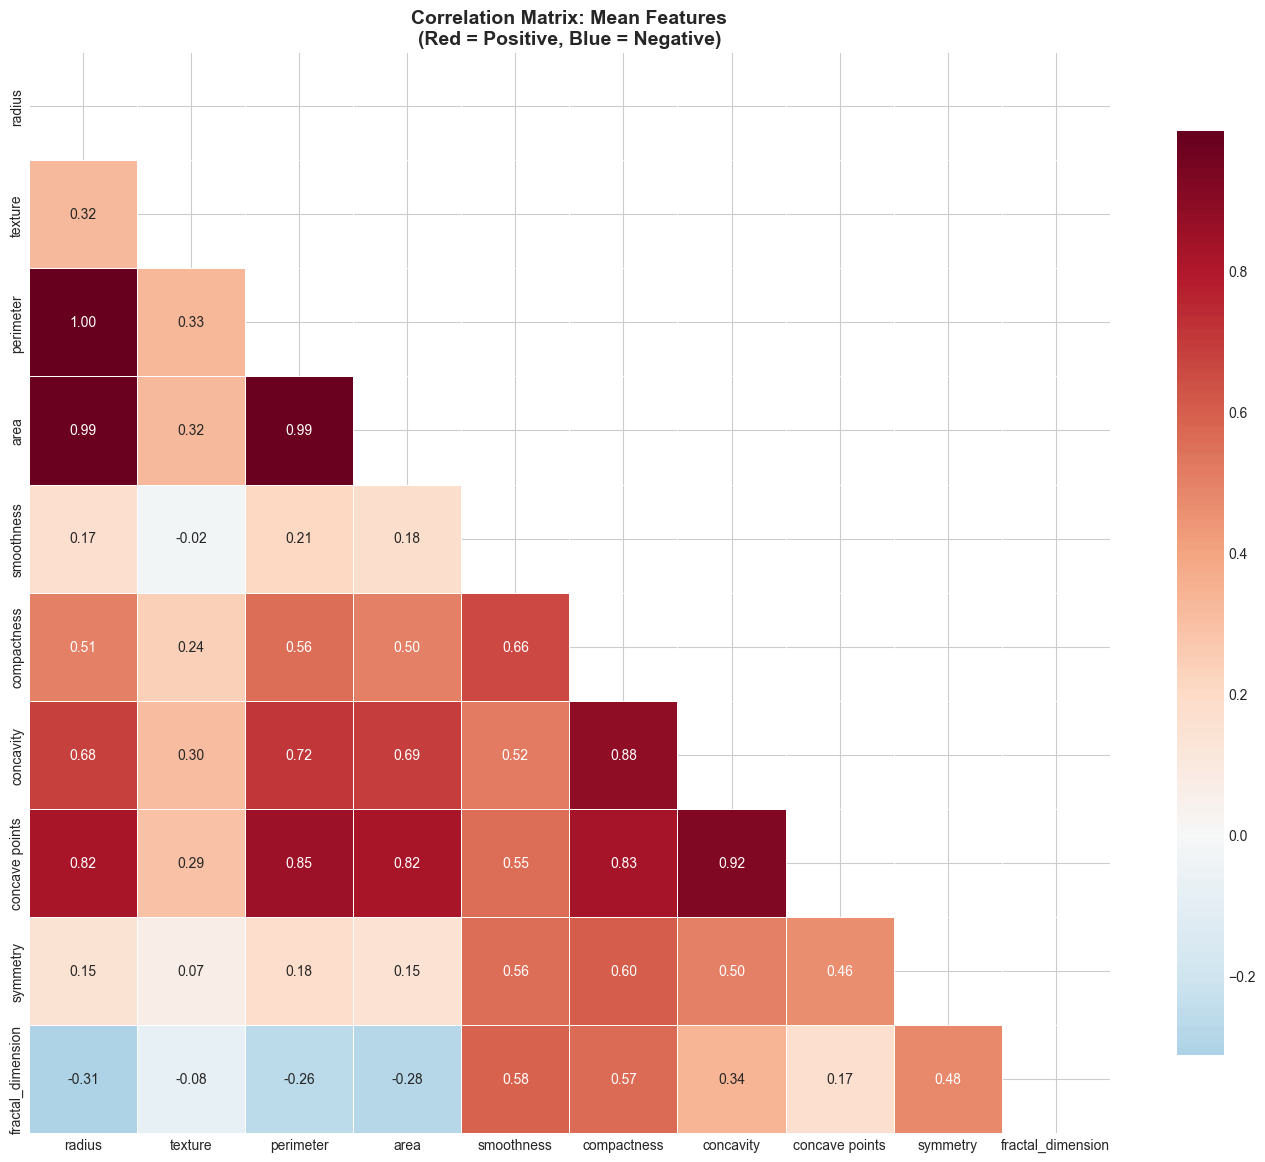


💡 INSIGHT: Look for highly correlated features (dark red/blue):
   • radius, perimeter, area are highly correlated (makes sense - they're related measurements)
   • concavity and concave points are highly correlated
   • This suggests some features might be redundant


In [15]:
# =============================================================================
# CORRELATION MATRIX FOR MEAN FEATURES
# =============================================================================

print("📊 CORRELATION ANALYSIS: Mean Features")
print("="*80)

# Calculate correlation matrix for mean features
corr_matrix = df_clean[mean_features].corr()

# Create heatmap
fig, ax = plt.subplots(figsize=(14, 12))

# Create mask for upper triangle (to avoid redundancy)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', 
            cmap='RdBu_r', center=0, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8},
            xticklabels=[f.replace('_mean', '') for f in mean_features],
            yticklabels=[f.replace('_mean', '') for f in mean_features])

plt.title('Correlation Matrix: Mean Features\n(Red = Positive, Blue = Negative)', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 INSIGHT: Look for highly correlated features (dark red/blue):")
print("   • radius, perimeter, area are highly correlated (makes sense - they're related measurements)")
print("   • concavity and concave points are highly correlated")
print("   • This suggests some features might be redundant")

📊 CORRELATION WITH DIAGNOSIS (Target Variable)

This shows which features are most related to the diagnosis.
Higher absolute values = stronger predictors.


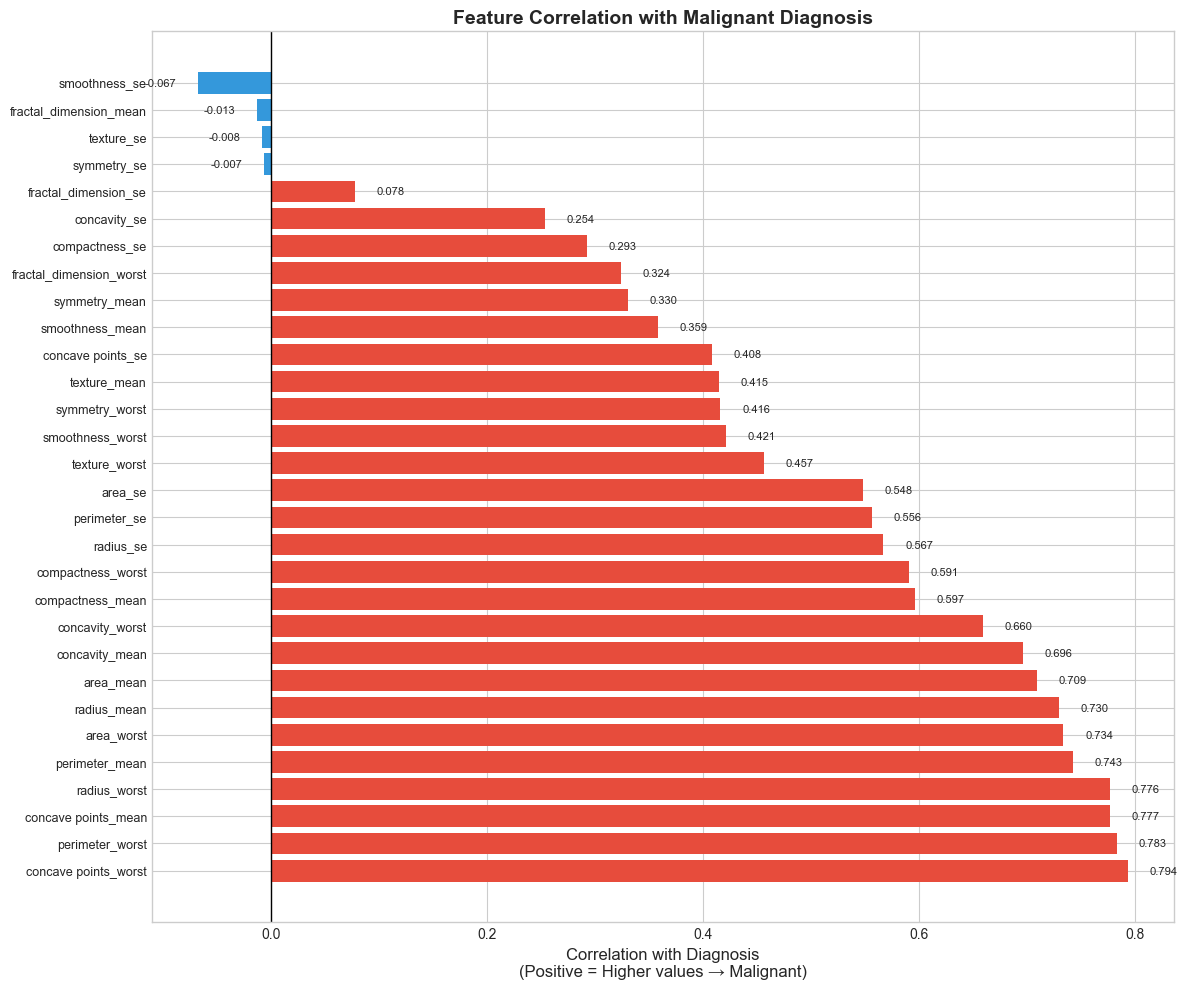


🎯 TOP 10 PREDICTORS (by correlation strength):
--------------------------------------------------
 1. concave points_worst           | r = +0.794 | ↑ Higher → Malignant
 2. perimeter_worst                | r = +0.783 | ↑ Higher → Malignant
 3. concave points_mean            | r = +0.777 | ↑ Higher → Malignant
 4. radius_worst                   | r = +0.776 | ↑ Higher → Malignant
 5. perimeter_mean                 | r = +0.743 | ↑ Higher → Malignant
 6. area_worst                     | r = +0.734 | ↑ Higher → Malignant
 7. radius_mean                    | r = +0.730 | ↑ Higher → Malignant
 8. area_mean                      | r = +0.709 | ↑ Higher → Malignant
 9. concavity_mean                 | r = +0.696 | ↑ Higher → Malignant
10. concavity_worst                | r = +0.660 | ↑ Higher → Malignant


In [16]:
# =============================================================================
# CORRELATION WITH TARGET VARIABLE
# =============================================================================

print("📊 CORRELATION WITH DIAGNOSIS (Target Variable)")
print("="*80)
print("\nThis shows which features are most related to the diagnosis.")
print("Higher absolute values = stronger predictors.")

# Calculate correlation with diagnosis_numeric
target_corr = df_clean[feature_columns + ['diagnosis_numeric']].corr()['diagnosis_numeric'].drop('diagnosis_numeric')
target_corr = target_corr.sort_values(ascending=False)

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))

colors = ['#e74c3c' if x > 0 else '#3498db' for x in target_corr]
bars = ax.barh(range(len(target_corr)), target_corr, color=colors)

ax.set_yticks(range(len(target_corr)))
ax.set_yticklabels(target_corr.index, fontsize=9)
ax.set_xlabel('Correlation with Diagnosis\n(Positive = Higher values → Malignant)', fontsize=12)
ax.set_title('Feature Correlation with Malignant Diagnosis', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linewidth=1)

# Add value labels
for i, (bar, val) in enumerate(zip(bars, target_corr)):
    ax.text(val + 0.02 if val > 0 else val - 0.02, i, f'{val:.3f}', 
            va='center', ha='left' if val > 0 else 'right', fontsize=8)

plt.tight_layout()
plt.show()

# Print top predictors
print("\n🎯 TOP 10 PREDICTORS (by correlation strength):")
print("-"*50)
top_predictors = target_corr.abs().sort_values(ascending=False).head(10)
for i, (feature, corr) in enumerate(top_predictors.items(), 1):
    direction = "↑ Higher → Malignant" if target_corr[feature] > 0 else "↓ Lower → Malignant"
    print(f"{i:2d}. {feature:30s} | r = {target_corr[feature]:+.3f} | {direction}")

📊 PAIRWISE SCATTER PLOTS: Top Predictors

These show relationships between pairs of features, colored by diagnosis.
Clear separation between colors = good for classification.


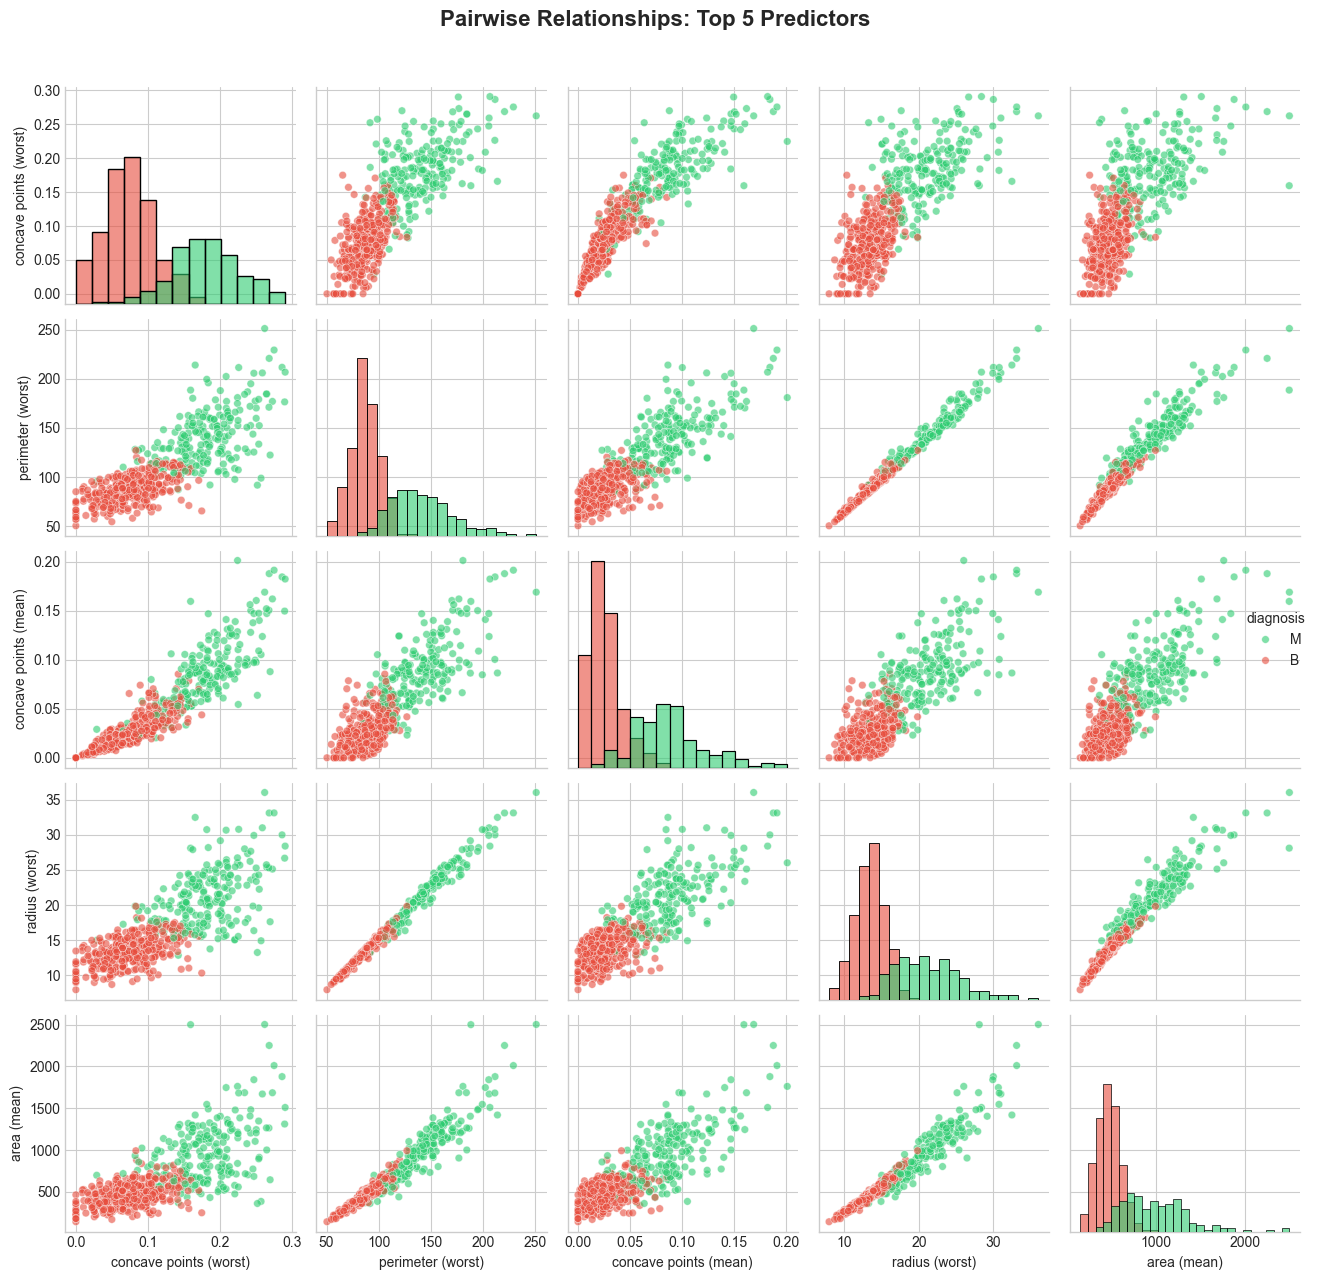

In [17]:
# =============================================================================
# PAIRWISE RELATIONSHIPS - SCATTER PLOTS
# =============================================================================

print("📊 PAIRWISE SCATTER PLOTS: Top Predictors")
print("="*80)
print("\nThese show relationships between pairs of features, colored by diagnosis.")
print("Clear separation between colors = good for classification.")

# Select top 5 features for pair plot
top_5_features = ['concave points_worst', 'perimeter_worst', 'concave points_mean',
                   'radius_worst', 'area_mean']

# Create pair plot
pair_df = df_clean[top_5_features + ['diagnosis']].copy()
pair_df.columns = [col.replace('_mean', ' (mean)').replace('_worst', ' (worst)') 
                   for col in pair_df.columns]

g = sns.pairplot(pair_df, hue='diagnosis', palette=['#2ecc71', '#e74c3c'],
                 diag_kind='hist', plot_kws={'alpha': 0.6, 's': 30},
                 diag_kws={'alpha': 0.6})

g.fig.suptitle('Pairwise Relationships: Top 5 Predictors', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.3 Outlier Detection

**What are Outliers?**

Outliers are data points that are significantly different from other observations. They can be:
- **Valid extremes**: Real but rare cases
- **Errors**: Data entry mistakes or measurement errors

**Detection Methods:**
- **IQR Method**: Points beyond 1.5 × Interquartile Range
- **Z-Score**: Points more than 3 standard deviations from mean

In [18]:
# =============================================================================
# OUTLIER DETECTION USING IQR METHOD
# =============================================================================

print("📊 OUTLIER ANALYSIS (IQR Method)")
print("="*80)
print("\nThe IQR (Interquartile Range) method identifies outliers as points")
print("that fall below Q1 - 1.5×IQR or above Q3 + 1.5×IQR.")

def count_outliers_iqr(data):
    """Count outliers using the IQR method"""
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((data < lower_bound) | (data > upper_bound)).sum()
    return outliers, lower_bound, upper_bound

# Analyze outliers for each feature
outlier_summary = []

for feature in mean_features:
    n_outliers, lower, upper = count_outliers_iqr(df_clean[feature])
    outlier_summary.append({
        'Feature': feature.replace('_mean', ''),
        'Outlier Count': n_outliers,
        'Outlier %': n_outliers / len(df_clean) * 100,
        'Lower Bound': lower,
        'Upper Bound': upper
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df = outlier_df.sort_values('Outlier Count', ascending=False)

print("\n📋 Outlier Summary (Mean Features):")
print(outlier_df.to_string(index=False))

print("\n💡 INSIGHT: Most features have some outliers, but the percentages are low.")
print("   In medical data, outliers might represent actual extreme cases.")
print("   We should be cautious about removing them without domain knowledge.")

📊 OUTLIER ANALYSIS (IQR Method)

The IQR (Interquartile Range) method identifies outliers as points
that fall below Q1 - 1.5×IQR or above Q3 + 1.5×IQR.

📋 Outlier Summary (Mean Features):
          Feature  Outlier Count  Outlier %  Lower Bound  Upper Bound
             area             25   4.393673  -123.300000  1326.300000
        concavity             18   3.163445    -0.122150     0.282410
      compactness             16   2.811951    -0.033300     0.228620
         symmetry             15   2.636204     0.111200     0.246400
fractal_dimension             15   2.636204     0.045070     0.078750
           radius             14   2.460457     5.580000    21.900000
        perimeter             13   2.284710    31.775000   147.495000
   concave points             10   1.757469    -0.060225     0.154535
          texture              7   1.230228     7.725000    30.245000
       smoothness              6   1.054482     0.057975     0.133695

💡 INSIGHT: Most features have some outlie

📊 OUTLIER VISUALIZATION


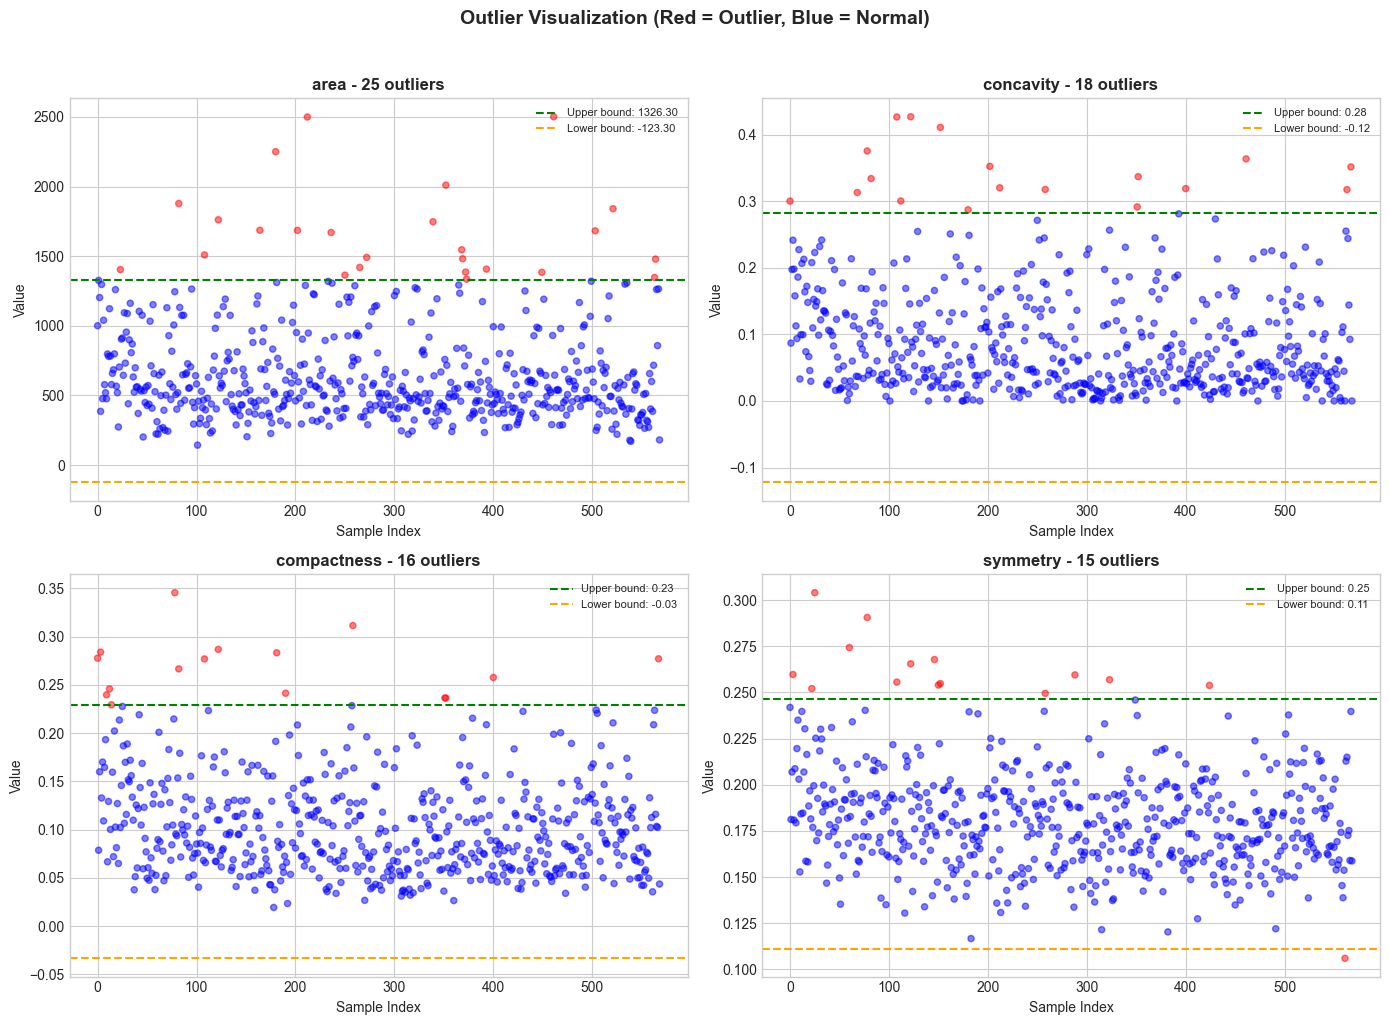

In [19]:
# =============================================================================
# OUTLIER VISUALIZATION
# =============================================================================

print("📊 OUTLIER VISUALIZATION")
print("="*80)

# Features with most outliers
high_outlier_features = outlier_df.head(4)['Feature'].tolist()
high_outlier_features = [f + '_mean' for f in high_outlier_features]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, feature in enumerate(high_outlier_features):
    ax = axes[idx]
    
    # Calculate bounds
    Q1 = df_clean[feature].quantile(0.25)
    Q3 = df_clean[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Identify outliers
    is_outlier = (df_clean[feature] < lower) | (df_clean[feature] > upper)
    
    # Create scatter plot
    ax.scatter(range(len(df_clean)), df_clean[feature], 
               c=['red' if x else 'blue' for x in is_outlier], alpha=0.5, s=20)
    ax.axhline(y=upper, color='green', linestyle='--', label=f'Upper bound: {upper:.2f}')
    ax.axhline(y=lower, color='orange', linestyle='--', label=f'Lower bound: {lower:.2f}')
    ax.set_title(f'{feature.replace("_mean", "")} - {is_outlier.sum()} outliers', 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Sample Index')
    ax.set_ylabel('Value')
    ax.legend(loc='upper right', fontsize=8)

plt.suptitle('Outlier Visualization (Red = Outlier, Blue = Normal)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## Part 6: Statistical Testing

### Why Statistical Testing?

While visualizations help us see patterns, statistical tests tell us if those patterns are **statistically significant** - i.e., unlikely to have occurred by chance.

### Key Concepts

**Hypothesis Testing:**
- **Null Hypothesis (H₀)**: No difference/relationship exists
- **Alternative Hypothesis (H₁)**: A difference/relationship exists
- **p-value**: Probability of seeing our results if H₀ is true
  - p < 0.05: Typically considered statistically significant
  - We "reject" H₀ and accept that a real difference exists

### Choosing the Right Test

| Data Type | Distribution | Test |
|-----------|-------------|------|
| Continuous | Normal | T-test |
| Continuous | Non-normal | Mann-Whitney U |
| Categorical vs Categorical | - | Chi-Square |

### 6.1 Testing for Normality

Before we can choose the right statistical test, we need to know if our data follows a **normal distribution** (bell curve).

**Shapiro-Wilk Test:**
- H₀: Data is normally distributed
- p < 0.05: Data is NOT normally distributed

In [20]:
# =============================================================================
# NORMALITY TESTING
# =============================================================================

print("📊 NORMALITY TESTING (Shapiro-Wilk Test)")
print("="*80)
print("\nH₀: Data is normally distributed")
print("H₁: Data is NOT normally distributed")
print("\nIf p-value < 0.05, we reject H₀ (data is not normal)")

normality_results = []

for feature in mean_features:
    # Test overall distribution
    stat, p_value = shapiro(df_clean[feature].sample(min(100, len(df_clean)), random_state=42))
    
    # Test for each diagnosis group
    stat_b, p_b = shapiro(df_clean[df_clean['diagnosis']=='B'][feature].sample(
        min(50, len(df_clean[df_clean['diagnosis']=='B'])), random_state=42))
    stat_m, p_m = shapiro(df_clean[df_clean['diagnosis']=='M'][feature].sample(
        min(50, len(df_clean[df_clean['diagnosis']=='M'])), random_state=42))
    
    normality_results.append({
        'Feature': feature.replace('_mean', ''),
        'Overall p-value': p_value,
        'Benign p-value': p_b,
        'Malignant p-value': p_m,
        'Is Normal (α=0.05)': 'Yes' if p_value > 0.05 else 'No'
    })

normality_df = pd.DataFrame(normality_results)
print("\n📋 Normality Test Results (Mean Features):")
print(normality_df.to_string(index=False))

# Summary
normal_count = (normality_df['Is Normal (α=0.05)'] == 'Yes').sum()
print(f"\n📊 Summary: {normal_count}/{len(normality_df)} features appear normally distributed")
print("\n💡 INSIGHT: Most features are NOT normally distributed.")
print("   This means we should use non-parametric tests (like Mann-Whitney U) for comparison.")

📊 NORMALITY TESTING (Shapiro-Wilk Test)

H₀: Data is normally distributed
H₁: Data is NOT normally distributed

If p-value < 0.05, we reject H₀ (data is not normal)

📋 Normality Test Results (Mean Features):
          Feature  Overall p-value  Benign p-value  Malignant p-value Is Normal (α=0.05)
           radius     3.631314e-04        0.579241           0.284067                 No
          texture     1.943234e-01        0.004900           0.435588                Yes
        perimeter     1.279176e-04        0.517414           0.491410                 No
             area     1.745138e-07        0.055547           0.334917                 No
       smoothness     4.658208e-01        0.107797           0.699589                Yes
      compactness     1.420504e-07        0.112560           0.001102                 No
        concavity     9.064735e-09        0.000080           0.046060                 No
   concave points     8.059941e-08        0.114335           0.060000           

📊 Q-Q PLOTS: Visual Normality Check

Q-Q plots compare our data distribution to a normal distribution.
If points follow the diagonal line, data is approximately normal.


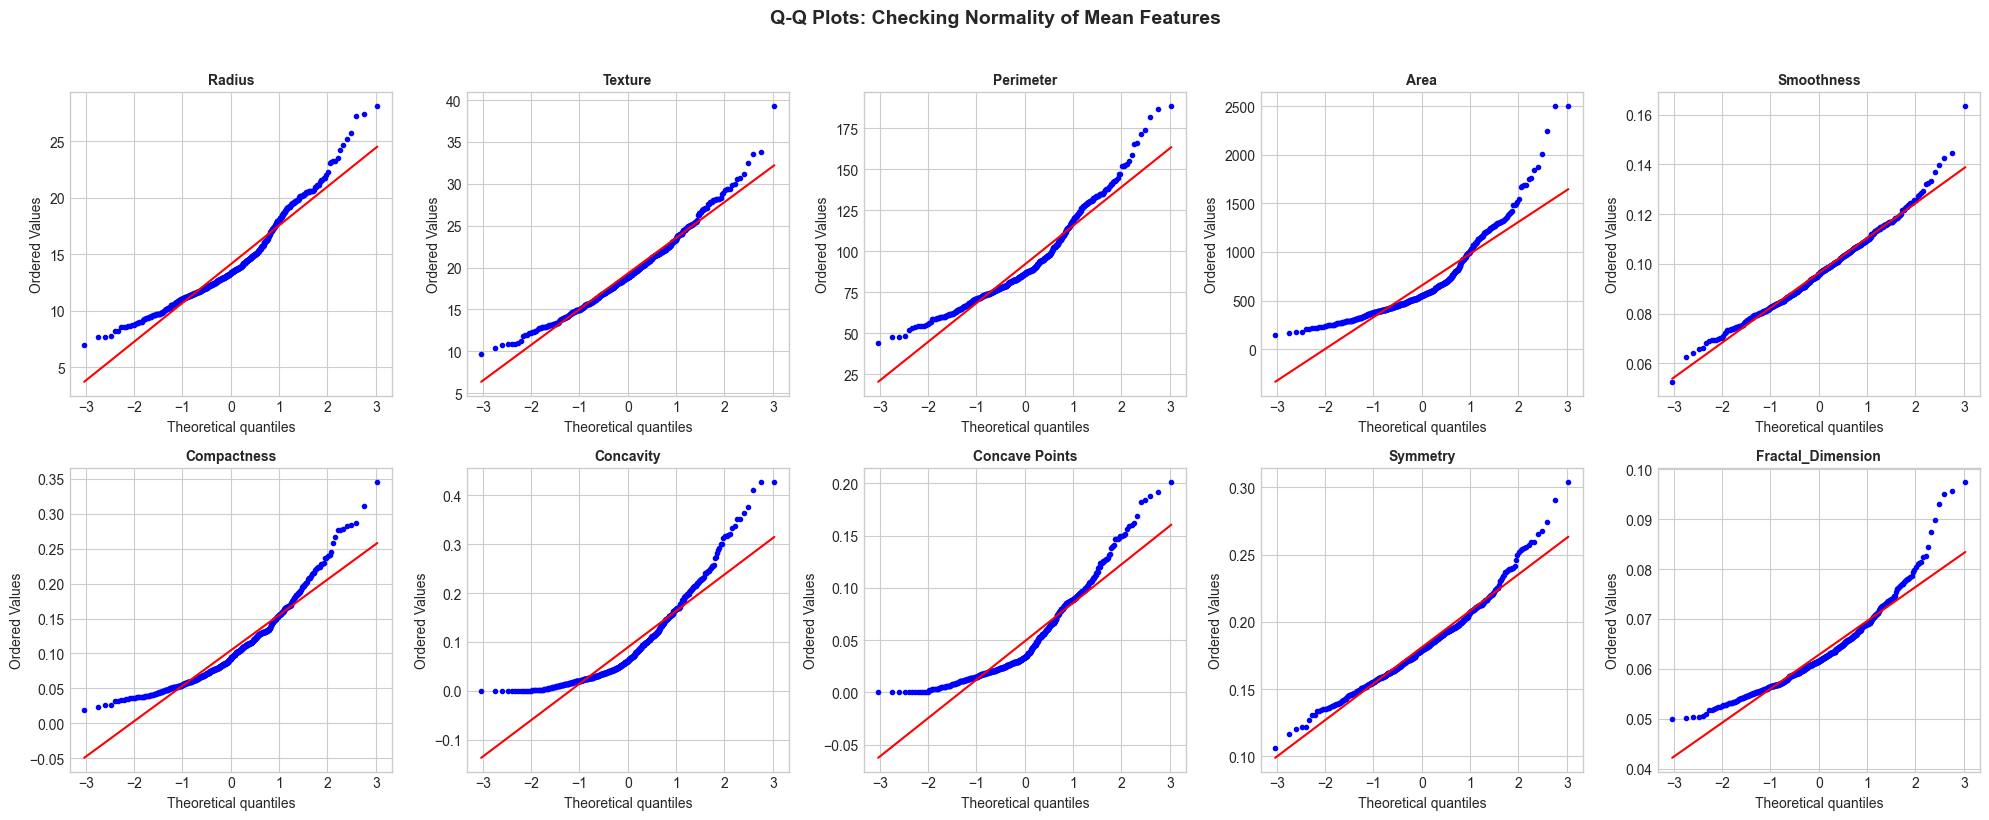


💡 Notice: Many features show deviations from the line (especially at tails),
   confirming our statistical test results that most features are not normal.


In [21]:
# =============================================================================
# Q-Q PLOTS FOR VISUAL NORMALITY CHECK
# =============================================================================

print("📊 Q-Q PLOTS: Visual Normality Check")
print("="*80)
print("\nQ-Q plots compare our data distribution to a normal distribution.")
print("If points follow the diagonal line, data is approximately normal.")

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for idx, feature in enumerate(mean_features):
    ax = axes[idx]
    stats.probplot(df_clean[feature], dist="norm", plot=ax)
    ax.set_title(feature.replace('_mean', '').title(), fontsize=10, fontweight='bold')
    ax.get_lines()[0].set_markersize(3)

plt.suptitle('Q-Q Plots: Checking Normality of Mean Features', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n💡 Notice: Many features show deviations from the line (especially at tails),")
print("   confirming our statistical test results that most features are not normal.")

### 6.2 Comparing Groups: Statistical Tests

Now let's formally test whether the differences we observed between Malignant and Benign tumors are statistically significant.

**Mann-Whitney U Test** (for non-normal data):
- Tests if one group tends to have larger values than another
- H₀: No difference between groups
- H₁: One group has significantly different values

In [22]:
# =============================================================================
# MANN-WHITNEY U TEST FOR GROUP COMPARISON
# =============================================================================

print("📊 MANN-WHITNEY U TEST: Comparing Malignant vs Benign")
print("="*80)
print("\nH₀: No difference in feature values between Malignant and Benign")
print("H₁: Significant difference exists between groups")
print("\nIf p-value < 0.05, the difference is statistically significant")

# Separate data by diagnosis
benign = df_clean[df_clean['diagnosis'] == 'B']
malignant = df_clean[df_clean['diagnosis'] == 'M']

comparison_results = []

for feature in feature_columns:
    # Mann-Whitney U test
    stat, p_value = mannwhitneyu(benign[feature], malignant[feature], alternative='two-sided')
    
    # Calculate effect size (rank-biserial correlation)
    n1, n2 = len(benign), len(malignant)
    effect_size = 1 - (2 * stat) / (n1 * n2)
    
    # Mean difference
    mean_diff = malignant[feature].mean() - benign[feature].mean()
    percent_diff = (mean_diff / benign[feature].mean()) * 100 if benign[feature].mean() != 0 else 0
    
    comparison_results.append({
        'Feature': feature,
        'U-statistic': stat,
        'p-value': p_value,
        'Significant (p<0.05)': 'Yes***' if p_value < 0.001 else ('Yes**' if p_value < 0.01 else ('Yes*' if p_value < 0.05 else 'No')),
        'Effect Size': effect_size,
        'Mean Diff (M-B)': mean_diff,
        '% Difference': percent_diff
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values('p-value')

print("\n📋 Statistical Test Results (sorted by significance):")
print("-"*100)
print(comparison_df.head(20).to_string(index=False))

# Summary
sig_count = (comparison_df['p-value'] < 0.05).sum()
print(f"\n📊 Summary: {sig_count}/{len(comparison_df)} features show statistically significant differences")
print("\n⭐ Significance levels: *** p<0.001, ** p<0.01, * p<0.05")

📊 MANN-WHITNEY U TEST: Comparing Malignant vs Benign

H₀: No difference in feature values between Malignant and Benign
H₁: Significant difference exists between groups

If p-value < 0.05, the difference is statistically significant

📋 Statistical Test Results (sorted by significance):
----------------------------------------------------------------------------------------------------
             Feature  U-statistic      p-value Significant (p<0.05)  Effect Size  Mean Diff (M-B)  % Difference
     perimeter_worst       1858.0 2.583004e-80               Yes***     0.950901        54.364392     62.483542
        radius_worst       2237.0 1.135630e-78               Yes***     0.940886         7.755010     57.960579
          area_worst       2283.5 1.803309e-78               Yes***     0.939657       863.386881    154.479826
concave points_worst       2520.0 1.863997e-77               Yes***     0.933407         0.107793    144.796717
 concave points_mean       2691.5 1.006324e-76       

📊 STATISTICAL SIGNIFICANCE VISUALIZATION


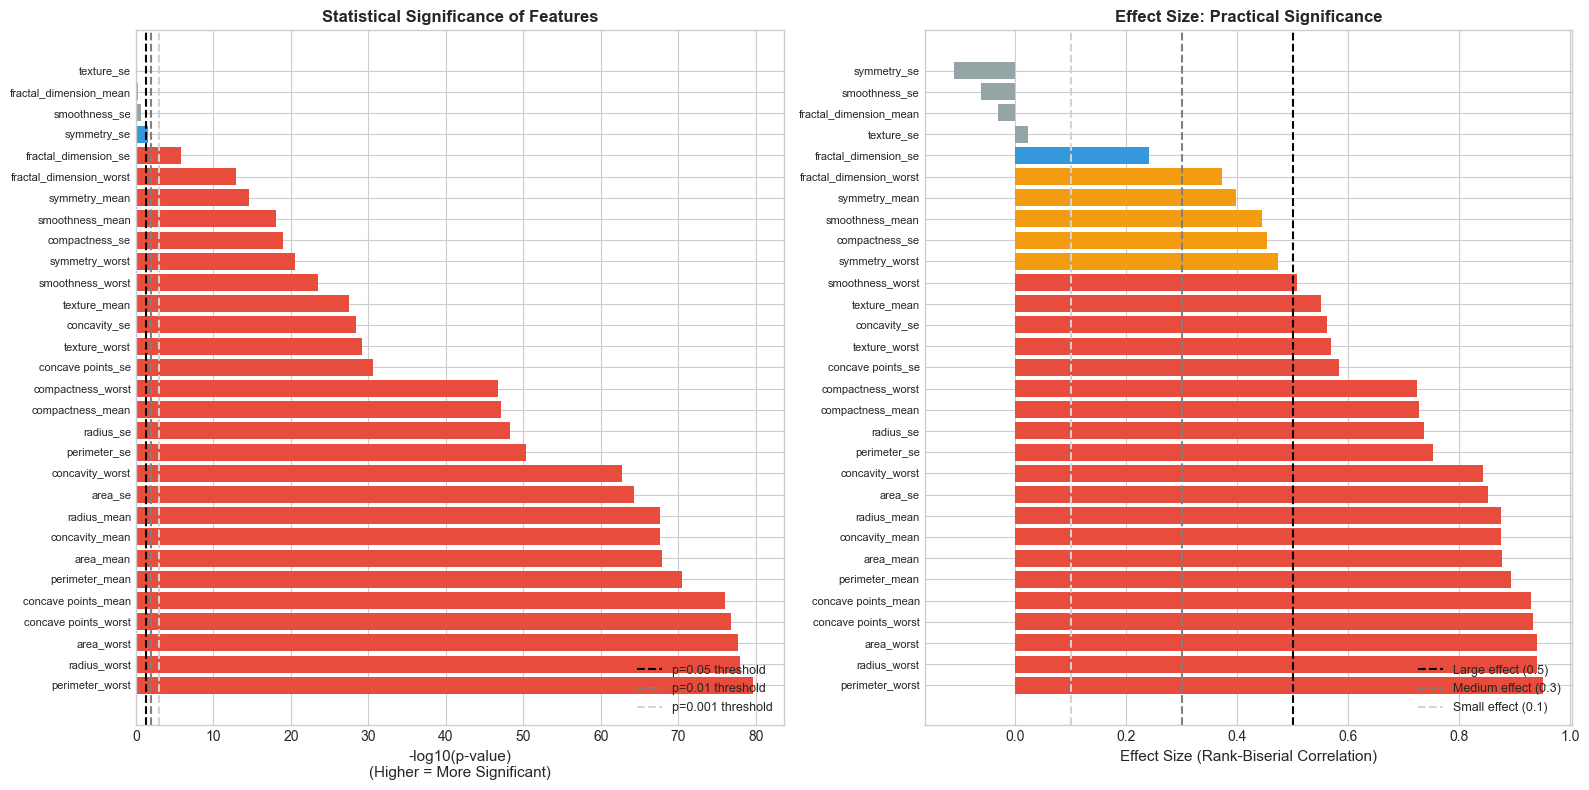


💡 KEY INSIGHT:
   • Statistical significance (p-value) tells us IF a difference exists
   • Effect size tells us HOW BIG that difference is
   • Both are important - a statistically significant but tiny difference may not be useful


In [23]:
# =============================================================================
# VISUALIZATION OF STATISTICAL SIGNIFICANCE
# =============================================================================

print("📊 STATISTICAL SIGNIFICANCE VISUALIZATION")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot 1: -log10(p-value) - higher = more significant
ax1 = axes[0]
sorted_df = comparison_df.sort_values('p-value')
log_pvalues = -np.log10(sorted_df['p-value'].values + 1e-300)  # Add small value to avoid log(0)

colors = ['#e74c3c' if p < 0.001 else ('#f39c12' if p < 0.01 else ('#3498db' if p < 0.05 else '#95a5a6')) 
          for p in sorted_df['p-value']]

ax1.barh(range(len(sorted_df)), log_pvalues, color=colors)
ax1.axvline(x=-np.log10(0.05), color='black', linestyle='--', label='p=0.05 threshold')
ax1.axvline(x=-np.log10(0.01), color='gray', linestyle='--', label='p=0.01 threshold')
ax1.axvline(x=-np.log10(0.001), color='lightgray', linestyle='--', label='p=0.001 threshold')
ax1.set_yticks(range(len(sorted_df)))
ax1.set_yticklabels(sorted_df['Feature'], fontsize=8)
ax1.set_xlabel('-log10(p-value)\n(Higher = More Significant)', fontsize=11)
ax1.set_title('Statistical Significance of Features', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right', fontsize=9)

# Plot 2: Effect size
ax2 = axes[1]
effect_sorted = comparison_df.sort_values('Effect Size', ascending=False)
colors2 = ['#e74c3c' if e > 0.5 else ('#f39c12' if e > 0.3 else ('#3498db' if e > 0.1 else '#95a5a6')) 
           for e in effect_sorted['Effect Size']]

ax2.barh(range(len(effect_sorted)), effect_sorted['Effect Size'], color=colors2)
ax2.axvline(x=0.5, color='black', linestyle='--', label='Large effect (0.5)')
ax2.axvline(x=0.3, color='gray', linestyle='--', label='Medium effect (0.3)')
ax2.axvline(x=0.1, color='lightgray', linestyle='--', label='Small effect (0.1)')
ax2.set_yticks(range(len(effect_sorted)))
ax2.set_yticklabels(effect_sorted['Feature'], fontsize=8)
ax2.set_xlabel('Effect Size (Rank-Biserial Correlation)', fontsize=11)
ax2.set_title('Effect Size: Practical Significance', fontsize=12, fontweight='bold')
ax2.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

print("\n💡 KEY INSIGHT:")
print("   • Statistical significance (p-value) tells us IF a difference exists")
print("   • Effect size tells us HOW BIG that difference is")
print("   • Both are important - a statistically significant but tiny difference may not be useful")

### 6.3 Additional Statistical Tests

In [24]:
# =============================================================================
# LEVENE'S TEST FOR EQUAL VARIANCES
# =============================================================================

print("📊 LEVENE'S TEST: Testing for Equal Variances")
print("="*80)
print("\nH₀: Variances are equal between groups")
print("H₁: Variances are NOT equal")
print("\nUnequal variances affect model performance and interpretation.")

variance_results = []

for feature in mean_features:
    stat, p_value = levene(benign[feature], malignant[feature])
    
    var_b = benign[feature].var()
    var_m = malignant[feature].var()
    
    variance_results.append({
        'Feature': feature.replace('_mean', ''),
        'Benign Variance': var_b,
        'Malignant Variance': var_m,
        'Variance Ratio': max(var_b, var_m) / min(var_b, var_m) if min(var_b, var_m) > 0 else np.inf,
        'p-value': p_value,
        'Equal Variances': 'Yes' if p_value > 0.05 else 'No'
    })

variance_df = pd.DataFrame(variance_results)
print("\n📋 Variance Equality Test Results:")
print(variance_df.to_string(index=False))

print("\n💡 INSIGHT: Features with unequal variances may behave differently in models.")

📊 LEVENE'S TEST: Testing for Equal Variances

H₀: Variances are equal between groups
H₁: Variances are NOT equal

Unequal variances affect model performance and interpretation.

📋 Variance Equality Test Results:
          Feature  Benign Variance  Malignant Variance  Variance Ratio      p-value Equal Variances
           radius         3.170222           10.265431        3.238080 5.279776e-20              No
          texture        15.961021           14.284393        1.117375 4.085768e-01             Yes
        perimeter       139.415582          477.625870        3.425915 3.792075e-20              No
             area     18033.030100       135378.355365        7.507244 3.312618e-34              No
       smoothness         0.000181            0.000159        1.137320 3.604436e-01             Yes
      compactness         0.001139            0.002915        2.558821 5.427750e-10              No
        concavity         0.001887            0.005628        2.982110 3.723189e-16     

📊 SPEARMAN CORRELATION: Feature Relationships

Spearman correlation is robust to non-normal distributions.
It measures monotonic relationships (not just linear).

📋 Top 15 Features by Spearman Correlation with Diagnosis:
             Feature  Spearman Correlation       p-value  Abs Correlation
     perimeter_worst              0.796319 6.742652e-126         0.796319
        radius_worst              0.787933 1.677735e-121         0.787933
          area_worst              0.786902 5.641911e-121         0.786902
concave points_worst              0.781674 2.387021e-118         0.781674
 concave points_mean              0.777877 1.736699e-116         0.777877
      perimeter_mean              0.748496 3.162795e-103         0.748496
           area_mean              0.734122  2.162221e-97         0.734122
      concavity_mean              0.733308  4.509903e-97         0.733308
         radius_mean              0.732785  7.219246e-97         0.732785
             area_se              0.714

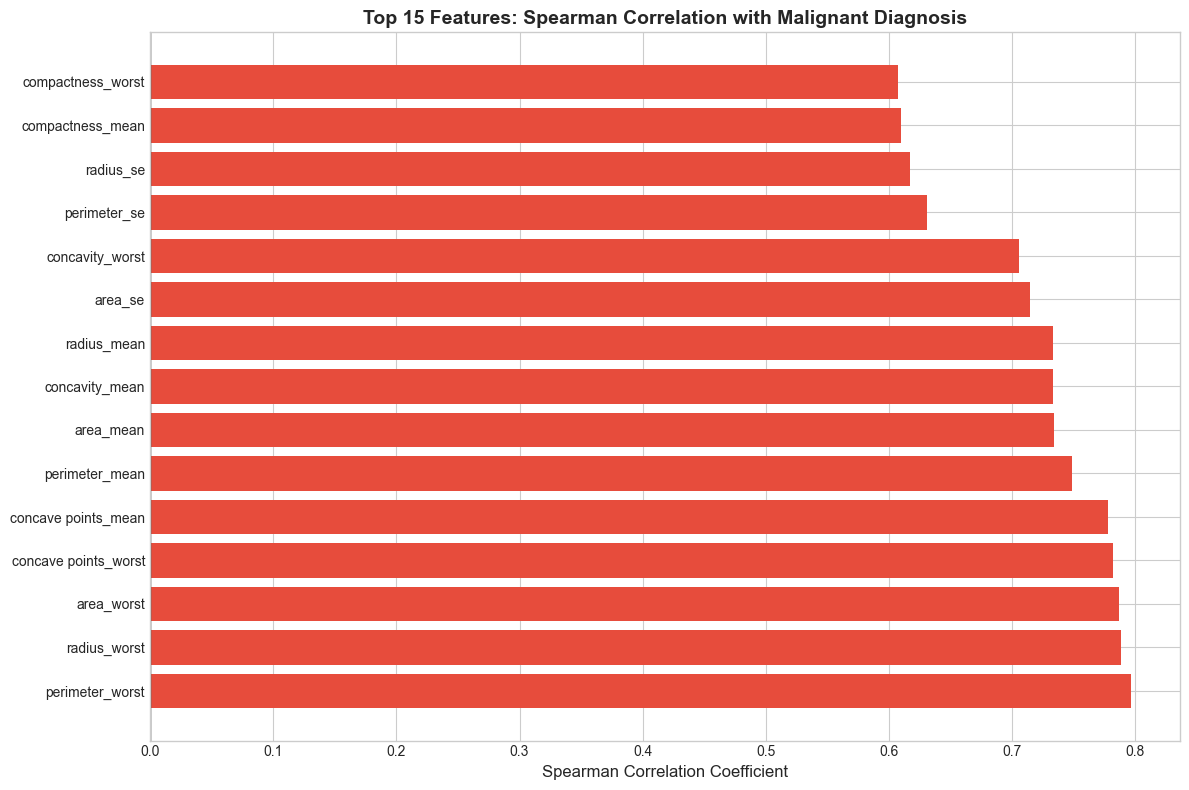

In [25]:
# =============================================================================
# SPEARMAN CORRELATION ANALYSIS
# =============================================================================

print("📊 SPEARMAN CORRELATION: Feature Relationships")
print("="*80)
print("\nSpearman correlation is robust to non-normal distributions.")
print("It measures monotonic relationships (not just linear).")

# Calculate Spearman correlation with target
spearman_results = []

for feature in feature_columns:
    corr, p_value = spearmanr(df_clean[feature], df_clean['diagnosis_numeric'])
    spearman_results.append({
        'Feature': feature,
        'Spearman Correlation': corr,
        'p-value': p_value,
        'Abs Correlation': abs(corr)
    })

spearman_df = pd.DataFrame(spearman_results)
spearman_df = spearman_df.sort_values('Abs Correlation', ascending=False)

print("\n📋 Top 15 Features by Spearman Correlation with Diagnosis:")
print(spearman_df.head(15).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 8))

top_15 = spearman_df.head(15)
colors = ['#e74c3c' if x > 0 else '#3498db' for x in top_15['Spearman Correlation']]

ax.barh(range(len(top_15)), top_15['Spearman Correlation'], color=colors)
ax.set_yticks(range(len(top_15)))
ax.set_yticklabels(top_15['Feature'])
ax.set_xlabel('Spearman Correlation Coefficient', fontsize=12)
ax.set_title('Top 15 Features: Spearman Correlation with Malignant Diagnosis', 
             fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linewidth=1)

plt.tight_layout()
plt.show()

---

## Part 7: Feature Importance Summary

Let's bring together all our findings to identify the most important features for classification.

In [26]:
# =============================================================================
# COMPREHENSIVE FEATURE IMPORTANCE SUMMARY
# =============================================================================

print("🎯 FEATURE IMPORTANCE SUMMARY")
print("="*80)
print("\nCombining multiple metrics to rank features by importance:")

# Merge all our analyses
summary_df = comparison_df[['Feature', 'p-value', 'Effect Size', '% Difference']].copy()
summary_df = summary_df.merge(spearman_df[['Feature', 'Spearman Correlation']], on='Feature')

# Normalize metrics to 0-1 scale for fair comparison
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Create importance scores (higher = better)
summary_df['Norm_Effect'] = scaler.fit_transform(summary_df[['Effect Size']].abs())
summary_df['Norm_Corr'] = scaler.fit_transform(summary_df[['Spearman Correlation']].abs())
summary_df['Norm_Sig'] = scaler.fit_transform(1 - summary_df[['p-value']])  # Invert so lower p = higher score

# Combined importance score (average of normalized metrics)
summary_df['Importance Score'] = (summary_df['Norm_Effect'] + summary_df['Norm_Corr'] + summary_df['Norm_Sig']) / 3

# Sort by importance
summary_df = summary_df.sort_values('Importance Score', ascending=False)

print("\n📋 Feature Rankings (Most to Least Important):")
print("-"*100)
display_df = summary_df[['Feature', 'Importance Score', 'Effect Size', 'Spearman Correlation', 'p-value']].copy()
display_df = display_df.reset_index(drop=True)
display_df.index = display_df.index + 1  # Start ranking from 1
print(display_df.head(15).to_string())

🎯 FEATURE IMPORTANCE SUMMARY

Combining multiple metrics to rank features by importance:

📋 Feature Rankings (Most to Least Important):
----------------------------------------------------------------------------------------------------
                 Feature  Importance Score  Effect Size  Spearman Correlation       p-value
1        perimeter_worst          1.000000     0.950901              0.796319  2.583004e-80
2           radius_worst          0.992804     0.940886              0.787933  1.135630e-78
3             area_worst          0.991920     0.939657              0.786902  1.803309e-78
4   concave points_worst          0.987431     0.933407              0.781674  1.863997e-77
5    concave points_mean          0.984174     0.928875              0.777877  1.006324e-76
6         perimeter_mean          0.958963     0.893795              0.748496  3.553870e-71
7              area_mean          0.946629     0.876632              0.734122  1.539780e-68
8         concavity_mean   

📊 TOP 10 PREDICTORS VISUALIZATION


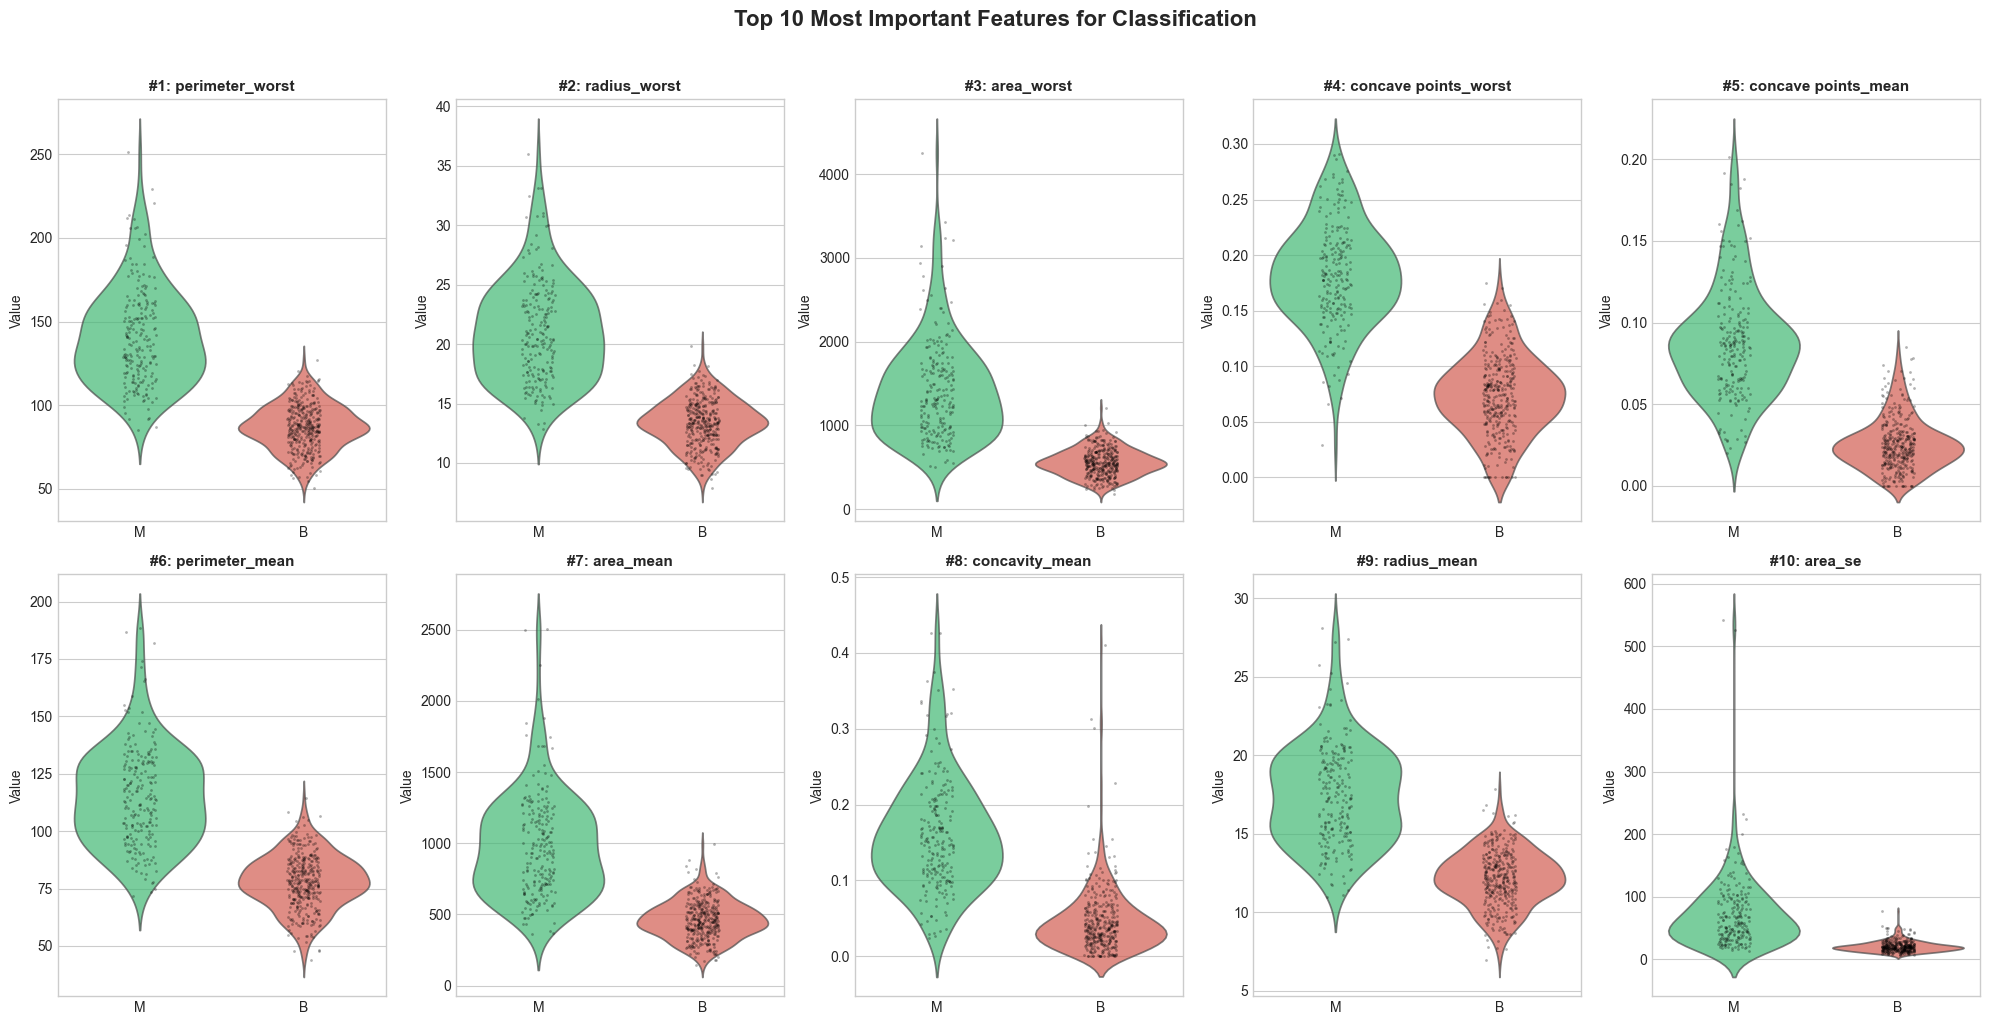

In [27]:
# =============================================================================
# FINAL VISUALIZATION: TOP PREDICTORS
# =============================================================================

print("📊 TOP 10 PREDICTORS VISUALIZATION")
print("="*80)

top_10 = summary_df.head(10)['Feature'].tolist()

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()

for idx, feature in enumerate(top_10):
    ax = axes[idx]
    
    # Create violin plot with strip plot overlay
    sns.violinplot(data=df_clean, x='diagnosis', y=feature, ax=ax,
                   palette=['#2ecc71', '#e74c3c'], inner=None, alpha=0.7)
    sns.stripplot(data=df_clean, x='diagnosis', y=feature, ax=ax,
                  color='black', alpha=0.3, size=2)
    
    # Add rank
    ax.set_title(f'#{idx+1}: {feature}', fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Value')

plt.suptitle('Top 10 Most Important Features for Classification', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## Part 8: Key Findings and Recommendations

### Summary of Our Analysis

In [28]:
# =============================================================================
# KEY FINDINGS SUMMARY
# =============================================================================

print("\n" + "="*80)
print("📋 KEY FINDINGS FROM OUR ANALYSIS")
print("="*80)

print("\n1️⃣ DATA QUALITY")
print("-"*40)
print(f"   • Dataset size: {len(df_clean)} samples")
print(f"   • Features: {len(feature_columns)} numeric features")
print(f"   • Missing values: None")
print(f"   • Duplicates: None")
print(f"   • Class distribution: {(df_clean['diagnosis']=='B').sum()} Benign ({(df_clean['diagnosis']=='B').mean()*100:.1f}%), "
      f"{(df_clean['diagnosis']=='M').sum()} Malignant ({(df_clean['diagnosis']=='M').mean()*100:.1f}%)")

print("\n2️⃣ STATISTICAL FINDINGS")
print("-"*40)
sig_features = (comparison_df['p-value'] < 0.05).sum()
print(f"   • {sig_features}/{len(feature_columns)} features show statistically significant differences")
print(f"   • Most features are NOT normally distributed (use non-parametric tests)")
print(f"   • Malignant tumors generally have LARGER measurements")

print("\n3️⃣ TOP PREDICTIVE FEATURES")
print("-"*40)
for i, feat in enumerate(summary_df.head(5)['Feature'].tolist(), 1):
    corr = spearman_df[spearman_df['Feature']==feat]['Spearman Correlation'].values[0]
    print(f"   {i}. {feat} (correlation: {corr:.3f})")

print("\n4️⃣ FEATURE CORRELATIONS")
print("-"*40)
print("   • radius, perimeter, area are highly correlated (redundant)")
print("   • concavity and concave points are highly correlated")
print("   • Consider feature selection to remove redundancy")

print("\n5️⃣ RECOMMENDATIONS FOR MODELING")
print("-"*40)
print("   • Address slight class imbalance (consider oversampling/undersampling)")
print("   • Scale features before modeling (different ranges)")
print("   • Consider feature selection to reduce multicollinearity")
print("   • Use stratified sampling for train/test split")
print("   • Start with interpretable models before complex ones")


📋 KEY FINDINGS FROM OUR ANALYSIS

1️⃣ DATA QUALITY
----------------------------------------
   • Dataset size: 569 samples
   • Features: 30 numeric features
   • Missing values: None
   • Duplicates: None
   • Class distribution: 357 Benign (62.7%), 212 Malignant (37.3%)

2️⃣ STATISTICAL FINDINGS
----------------------------------------
   • 27/30 features show statistically significant differences
   • Most features are NOT normally distributed (use non-parametric tests)
   • Malignant tumors generally have LARGER measurements

3️⃣ TOP PREDICTIVE FEATURES
----------------------------------------
   1. perimeter_worst (correlation: 0.796)
   2. radius_worst (correlation: 0.788)
   3. area_worst (correlation: 0.787)
   4. concave points_worst (correlation: 0.782)
   5. concave points_mean (correlation: 0.778)

4️⃣ FEATURE CORRELATIONS
----------------------------------------
   • radius, perimeter, area are highly correlated (redundant)
   • concavity and concave points are highly cor

---

## Part 9: Next Steps - Preparing for Machine Learning

This EDA has prepared us for the next phases of our project:

### Coming Up:

1. **Black Box Models**
   - Random Forest
   - Gradient Boosting (XGBoost, LightGBM)
   - Neural Networks
   - These are powerful but hard to interpret

2. **Surrogate Models**
   - Simple models that approximate complex ones
   - Decision Trees, Linear Models
   - Help us understand what the black box is doing

3. **Explainable AI (XAI) Tools**
   - SHAP (SHapley Additive exPlanations)
   - LIME (Local Interpretable Model-agnostic Explanations)
   - Feature importance visualizations
   - These help us explain predictions to stakeholders

### Why XAI Matters in Healthcare

In medical applications, we can't just say "the model says it's malignant." We need to:
- Explain WHY the model made that prediction
- Identify which features were most influential
- Build trust with medical professionals
- Meet regulatory requirements

In [29]:
# =============================================================================
# SAVE CLEAN DATA FOR NEXT PHASE
# =============================================================================

print("💾 SAVING PREPARED DATA FOR MODELING")
print("="*80)

# Save the clean dataframe
df_clean.to_csv('breast_cancer_cleaned.csv', index=False)
print("\n✅ Saved: breast_cancer_cleaned.csv")

# Save feature importance rankings
summary_df.to_csv('feature_importance_rankings.csv', index=False)
print("✅ Saved: feature_importance_rankings.csv")

print("\n🎉 EDA COMPLETE! Ready for modeling phase.")

💾 SAVING PREPARED DATA FOR MODELING

✅ Saved: breast_cancer_cleaned.csv
✅ Saved: feature_importance_rankings.csv

🎉 EDA COMPLETE! Ready for modeling phase.


---

## 📚 Glossary of Terms

| Term | Definition |
|------|------------|
| **EDA** | Exploratory Data Analysis - investigating data before modeling |
| **Target Variable** | What we're trying to predict (diagnosis in our case) |
| **Feature** | An input variable used for prediction |
| **Correlation** | Measure of relationship between two variables (-1 to +1) |
| **p-value** | Probability of seeing results if null hypothesis is true |
| **Effect Size** | Magnitude of difference (practical significance) |
| **Normal Distribution** | Bell-shaped curve where most values are near the mean |
| **Non-parametric** | Statistical methods that don't assume specific distributions |
| **Outlier** | Data point significantly different from others |
| **Class Imbalance** | When one category has many more samples than another |

---

## Questions?

Feel free to explore the code cells and modify them to deepen your understanding. Key areas to experiment with:

1. Try different visualization parameters
2. Run statistical tests on different feature groups
3. Explore correlations between specific features
4. Investigate outliers in more detail